# Wildlife Re-ID

**What this notebook does.** One reproducible pipeline that builds four model versions, scores each with the *same* open-set cross-validation, explains where each gain comes from, and writes one submission file per version.

| Version | Idea | Main new ingredient |
|---|---|---|
| **V1** baseline | cosine similarity on L2-normalised MiewID descriptors, best-image-per-identity, a threshold for `new_individual` | – |
| **V2** (earlier best) | centre + PCA-whiten → k-reciprocal re-ranking → SIFT/RANSAC verification → hand-tuned blend → top-2 identity aggregation → per-species τ | local-feature geometry |
| **V3** | a **learned identity ranker** (gradient boosting over per-identity evidence) + a **learned P(new_individual)** model; the two probabilities are sorted together | learning instead of hand-tuned weights; open-set decision as a probability |
| **V4** (new) | V3 + a **supervised linear projection** (within-class whitening) that adds similarity channels and extra SIFT-verified candidates, trained on a **similarity-aware CV** as well, followed by a **transductive stage 2** in which SIFT-verified neighbouring queries support each other | metric learning on the given features; query-query verification |

**What changed and why**

* *(b) Performance gains across versions* → every version is evaluated on the same folds, plus a cumulative **ablation table** (A→F) that isolates each component.
* *(c) Error analysis* → failure taxonomy, MAP by viewpoint / identity-frequency / keypoint-count, SIFT evidence histogram, calibration of P(new), feature importance, and a limitations section.
* *Validation fix* → the CV now **simulates new individuals** (whole identities are held out), so the `new_individual` logic is tuned on a realistic open-set problem, not only on closed-set queries.
* *Similarity-aware CV* → a second, harder CV (`hard`) holds out whole clusters of look-alike images of each known identity; every learned model is trained on both schemes and every row of the results table is scored under both.
* *Learned projection* → within-class covariance whitening fitted on the gallery only (inside every fold) adds image-level and identity-centroid cosine channels and proposes up to `CAND_LDA` extra candidate images per query.
* *Transductive stage 2* → the `KN` nearest queries of each query are SIFT-verified and their stage-1 identity probabilities are propagated; stage 2 is used for `submission.csv` only if it beats stage 1 under both CV schemes.
* *Focused learners* → the learned models only see the `TOP_ID` best candidate identities per query (+ `TOP_L` from the learned space).

In [1]:
import os, sys, json, time, glob, hashlib, warnings, threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 0
np.random.seed(SEED)
T_START = time.time()
def log(*a): print(f"[{time.time() - T_START:6.0f}s]", *a, flush=True)

def _env_int(name, default): return int(os.environ.get(name, default))

DATA_DIR = "C:/Users/anupd/Documents/wildlife-reid/reid_student_data_main"
PARENT_DIR = "C:/Users/anupd/Documents/wildlife-reid"
assert os.path.isfile(os.path.join(DATA_DIR, "train.csv")), f"train.csv not found in {DATA_DIR}"
CACHE_DIR, FIG_DIR = os.environ.get("CACHE_DIR", "cache"), "figures"
OUT_DIR    = os.environ.get("OUT_DIR", ".")
for d in (CACHE_DIR, FIG_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)

NEW, SPECIES = "new_individual", ["hyena", "leopard"]
SP_ID = {s: i for i, s in enumerate(SPECIES)}

# ---------- pipeline settings ----------
N_FOLDS        = _env_int("N_FOLDS", 5)
NEW_QUERY_FRAC = 0.40
PCA_DIM        = _env_int("PCA_DIM", 512)
RERANK_K1, RERANK_K2, RERANK_LAM = 20, 6, 0.3
CAND_K, TOP_M_SIFT = _env_int("CAND_K", 300), _env_int("TOP_M_SIFT", 150)
SIFT_RATIO, RANSAC_THRESH, RANSAC_ITERS = 0.78, 5.0, 2000
KN             = 5
NN_STRONG      = 8
TOP_ID         = _env_int("TOP_ID", 30)
TOP_L          = _env_int("TOP_L", 10)
CAND_LDA       = _env_int("CAND_LDA", 60)
ALPHAS         = [1.0, 0.6, 0.35, 0.2, 0.1, 0.05, 0.02, 0.01]
FAST           = os.environ.get("FAST", "0") == "1"
MODEL_FOLDS    = 5
TOP_M_EFF      = TOP_M_SIFT + CAND_LDA
SUBMIT_VERSION = "v4"
assert CAND_K >= TOP_M_EFF

# V2 hand-tuned parameters from the previous notebook (full precision file is used if present)
BEST_PARAMS = dict(w_rerank=0.2812, w_sift=0.1906, b_same=-0.0062, b_adj=0.0094, b_opp=0.0125, agg="top2", floor=3)
_cfgp = next((p for p in [os.path.join(d, "best_config_v2.json") for d in [".", DATA_DIR, PARENT_DIR]] if os.path.isfile(p)), None)
if _cfgp:
    BEST_PARAMS = json.load(open(_cfgp))["params"]; print("Loaded V2 params from", _cfgp)
assert SUBMIT_VERSION in ("v1", "v2", "v3", "v4")
print("DATA_DIR:", DATA_DIR, "| folds:", N_FOLDS, "| new-share target:", NEW_QUERY_FRAC, "| FAST:", FAST)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150); plt.show()

DATA_DIR: C:/Users/anupd/Documents/wildlife-reid/reid_student_data_main | folds: 5 | new-share target: 0.4 | FAST: False


## 1. Load data

In [2]:
def load_data(d=DATA_DIR):
    tr = pd.read_csv(f"{d}/train.csv"); te = pd.read_csv(f"{d}/test.csv")
    ids = pd.read_csv(f"{d}/miewid_ids.csv")
    col = "id" if "id" in ids.columns else ids.columns[0]
    F = np.load(f"{d}/miewid_features.npy").astype(np.float32)
    pos = pd.Series(np.arange(len(ids)), index=ids[col].to_numpy())
    Xtr, Xte = F[pos.loc[tr.id.to_numpy()].to_numpy()], F[pos.loc[te.id.to_numpy()].to_numpy()]   # KeyError if ids misalign
    for df in (tr, te): df["viewpoint"] = df["viewpoint"].fillna("unk").astype(str)
    return tr, te, Xtr, Xte

tr, te, Xtr, Xte = load_data()
print(tr.shape, te.shape, Xtr.shape, Xte.shape)
CLASSES, code_tr = np.unique(tr.identity.astype(str).to_numpy(), return_inverse=True)   # one global code per identity
code_tr = code_tr.astype(np.int32)
print(tr.groupby("species").identity.agg(["size", "nunique"]))
print("identities with a single training image:", int((tr.identity.value_counts() == 1).sum()))

(7163, 4) (2791, 3) (7163, 2152) (2791, 2152)
         size  nunique
species               
hyena    1912      205
leopard  5251      345
identities with a single training image: 102


## 2. Metric and an **open-set** cross-validation

In [3]:
NEG = -1e6
def ap5(pred, truth):
    for r, p in enumerate(pred[:5]):
        if p == truth: return 1.0 / (r + 1)
    return 0.0
def map5(preds, truths): return float(np.mean([ap5(p, t) for p, t in zip(preds, truths)]))

def make_open_set_folds(tr, hard=False, k=N_FOLDS, new_frac=NEW_QUERY_FRAC, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = tr.groupby("identity").indices                          # identity -> row positions
    sizes = pd.Series({i: len(r) for i, r in groups.items()})
    unseen = set(sizes.index[sizes == 1])                            # singletons can never be "known" queries
    n_unseen = len(unseen)
    for i in rng.permutation(sizes.index[sizes >= 2].to_numpy()):
        if n_unseen >= new_frac * len(tr): break
        unseen.add(i); n_unseen += sizes[i]
    fold = np.zeros(len(tr), int); is_unseen = np.zeros(len(tr), bool); multi = 0
    for ident, rows in groups.items():
        if ident in unseen:
            fold[rows] = rng.integers(k); is_unseen[rows] = True     # all images of an unseen identity share a fold
            continue
        if hard and len(rows) >= 3:
            Es = E_TR[rows]; Dm = np.clip(1.0 - Es @ Es.T, 0, None); np.fill_diagonal(Dm, 0); Dm = (Dm + Dm.T) / 2
            lab = fcluster(linkage(squareform(Dm, checks=False), "average"), t=int(np.clip(round(len(rows) / 4), 2, len(rows))), criterion="maxclust") - 1
            nc = int(lab.max()) + 1
            if nc >= 2:
                order = rng.permutation(nc); start = rng.integers(k); cf = np.empty(nc, int); cf[order] = (start + np.arange(nc)) % k
                fold[rows] = cf[lab]; multi += len(rows); continue
        rows = rng.permutation(rows); start = rng.integers(k)
        fold[rows] = (start + np.arange(len(rows))) % k          # spread over folds -> a gallery image always remains
    if hard: log(f"  hard folds: {multi} of {int((~is_unseen).sum())} known-identity images were split by look-alike cluster")
    return fold, is_unseen

FOLDS = {"rand": make_open_set_folds(tr)}
fold_tr, unseen_tr = FOLDS["rand"]
print("share of train images that act as 'new' queries: %.1f%%" % (100 * unseen_tr.mean()))
print("queries per fold:", np.bincount(fold_tr, minlength=N_FOLDS))

share of train images that act as 'new' queries: 40.3%
queries per fold: [1179 1501 1477 1076 1930]


## 3. Embeddings (per species; species are never mixed)

* **RAW**: L2-normalised MiewID descriptor (used by V1).
* **PCA**: L2-norm → subtract mean → L2-norm → PCA(512, whiten) → L2-norm (used by V2/V3). Whitening equalises the variance of every component so no single dominant direction dominates the cosine.

In [4]:
def l2n(X): return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)

def pca_embed(Xtr_sp, Xte_sp, dim=None):
    dim = dim or PCA_DIM
    X = l2n(np.vstack([Xtr_sp, Xte_sp]).astype(np.float32))
    X = l2n(X - X.mean(0, keepdims=True))
    dim = min(dim, X.shape[0] - 1, X.shape[1])
    X = l2n(PCA(dim, whiten=True, random_state=SEED).fit_transform(X).astype(np.float32))   # unsupervised: no labels used
    return X[:len(Xtr_sp)], X[len(Xtr_sp):]

PCA_DIM = min(PCA_DIM, min(int((tr.species == s_).sum() + (te.species == s_).sum()) for s_ in SPECIES) - 1)
SUB, TE_SUB, EMB, RAW = {}, {}, {}, {}
for sp in SPECIES:
    m_tr, m_te = (tr.species == sp).to_numpy(), (te.species == sp).to_numpy()
    SUB[sp], TE_SUB[sp] = np.flatnonzero(m_tr), np.flatnonzero(m_te)
    EMB[sp] = pca_embed(Xtr[m_tr], Xte[m_te])
    RAW[sp] = (l2n(Xtr[m_tr]), l2n(Xte[m_te]))
    print(f"{sp}: train={m_tr.sum()} test={m_te.sum()} identities={len(np.unique(code_tr[m_tr]))}")

hyena: train=1912 test=1217 identities=205
leopard: train=5251 test=1574 identities=345


### 3b. Similarity-aware (hard) folds
Each known identity is cut into clusters of look-alike images (average linkage on the PCA embedding) and whole clusters are held out together, so a query's nearest siblings are not in its gallery. `MF_TR` gives identity-grouped folds for the learned models.

In [5]:
E_TR = np.zeros((len(tr), EMB[SPECIES[0]][0].shape[1]), np.float32)
for sp in SPECIES: E_TR[SUB[sp]] = EMB[sp][0]
FOLDS["hard"] = make_open_set_folds(tr, hard=True, seed=SEED + 7)
SCH = ("rand", "hard")
for k_, (f_, u_) in FOLDS.items(): log(f"CV scheme {k_}: new-query share {100 * u_.mean():.1f}% | queries per fold {np.bincount(f_, minlength=N_FOLDS).tolist()}")

_rg = np.random.default_rng(SEED + 99)
_gmap = dict(zip(CLASSES, _rg.integers(MODEL_FOLDS, size=len(CLASSES))))
MF_TR = np.array([_gmap[c] for c in tr.identity.astype(str)], dtype=np.int8)

[   143s]   hard folds: 4010 of 4072 known-identity images were split by look-alike cluster
[   143s] CV scheme rand: new-query share 40.3% | queries per fold [1179, 1501, 1477, 1076, 1930]
[   143s] CV scheme hard: new-query share 43.2% | queries per fold [1293, 1296, 1318, 1598, 1658]


### 3c. Supervised linear projection (within-class whitening)
`ALPHA` is the shrinkage towards the identity (1.0 = no projection), chosen per species on the `rand` folds by closed-set top-1 accuracy. In every fold and for the test set the projection is fitted on the gallery only.

In [6]:
def within_scatter(X, y):
    u, inv = np.unique(y, return_inverse=True)
    M = sparse.csr_matrix((np.ones(len(y), np.float32), (inv, np.arange(len(y)))), shape=(len(u), len(y)))
    means = (M @ X) / np.asarray(M.sum(1)).ravel()[:, None]
    Xc = (X - means[inv]).astype(np.float64)
    return Xc.T @ Xc / max(len(y) - len(u), 1)

def wccn_matrix(Sw, alpha):
    d = Sw.shape[0]; S = (1 - alpha) * Sw + alpha * np.trace(Sw) / d * np.eye(d)
    ev, V = np.linalg.eigh(S); ev = np.maximum(ev, 1e-8 * ev.max())
    return ((V * ev ** -0.5) @ V.T).astype(np.float32)

def fit_proj(Pg, yg, alpha, Sw=None):
    Sw = within_scatter(Pg, yg) if Sw is None else Sw
    return Pg.mean(0), wccn_matrix(Sw, alpha)
def apply_proj(X, mu, W): return l2n((X - mu) @ W)

def select_alpha(sp):
    rows = SUB[sp]; P_tr = EMB[sp][0]; f = FOLDS["rand"][0][rows]; un = FOLDS["rand"][1][rows]; y = code_tr[rows]
    acc = {a: [] for a in ALPHAS}
    for k in range(N_FOLDS):
        g, q = f != k, (f == k) & ~un
        if q.sum() == 0: continue
        Sw = within_scatter(P_tr[g], y[g])
        for a in ALPHAS:
            mu, W = fit_proj(P_tr[g], y[g], a, Sw)
            pred = y[g][np.argmax(apply_proj(P_tr[q], mu, W) @ apply_proj(P_tr[g], mu, W).T, 1)]
            acc[a].append(float((pred == y[q]).mean()))
    m = {a: float(np.mean(v)) for a, v in acc.items()}
    best = max(m, key=m.get)
    log(f"  projection shrinkage {sp}: " + " ".join(f"a={a}:{m[a]:.4f}" for a in ALPHAS) + f"  -> a={best}")
    return best, m

ALPHA, ALPHA_TAB = {}, {}
for sp in SPECIES: ALPHA[sp], ALPHA_TAB[sp] = select_alpha(sp)

[   156s]   projection shrinkage hyena: a=1.0:0.8612 a=0.6:0.8691 a=0.35:0.8762 a=0.2:0.8860 a=0.1:0.8889 a=0.05:0.8896 a=0.02:0.8875 a=0.01:0.8860  -> a=0.05
[   164s]   projection shrinkage leopard: a=1.0:0.8459 a=0.6:0.8507 a=0.35:0.8500 a=0.2:0.8507 a=0.1:0.8507 a=0.05:0.8507 a=0.02:0.8511 a=0.01:0.8521  -> a=0.01


## 4. k-reciprocal re-ranking

In [7]:
def k_reciprocal_rerank(Q, G, k1=RERANK_K1, k2=RERANK_K2, lam=RERANK_LAM, chunk=1024):
    """Q (nq,d), G (ng,d): L2-normalised. Returns (S_rerank (nq,ng), S_cos (nq,ng))."""
    Q = np.ascontiguousarray(Q, dtype=np.float32); G = np.ascontiguousarray(G, dtype=np.float32)
    nq, ng = len(Q), len(G)
    X = np.vstack([Q, G]); N = nq + ng
    S_cos = Q @ G.T
    kk = min(k1, N - 1)
    D = np.empty((N, N), np.float32)                      # row-max-normalised squared euclidean distance
    nn = np.empty((N, kk + 1), np.int32)
    for a in range(0, N, chunk):
        b = min(a + chunk, N)
        d = 2.0 - 2.0 * (X[a:b] @ X.T)
        np.maximum(d, 0, out=d)
        d /= np.maximum(d.max(1, keepdims=True), 1e-12)
        D[a:b] = d
        part = np.argpartition(d, kk, axis=1)[:, :kk + 1]
        o = np.argsort(np.take_along_axis(d, part, 1), axis=1)
        nn[a:b] = np.take_along_axis(part, o, 1)
    ar = np.arange(N)
    for i in np.flatnonzero(nn[:, 0] != ar):             # exact duplicates can displace self from position 0
        w = np.flatnonzero(nn[i] == i)
        if len(w): nn[i, [0, w[0]]] = nn[i, [w[0], 0]]
        else:      nn[i] = np.r_[i, nn[i, :-1]]
    rec = (nn[nn] == ar[:, None, None]).any(2)
    h = min(int(round(k1 / 2)), kk)
    nnh = nn[:, :h + 1]
    rech = (nnh[nnh] == ar[:, None, None]).any(2)
    Rfull = [nn[i][rec[i]] for i in range(N)]
    Rhalf = [set(nnh[i][rech[i]].tolist()) for i in range(N)]
    rows, cols, vals = [], [], []
    for i in range(N):
        R = Rfull[i]; Rset = set(R.tolist()); add = set()
        for c in R.tolist():
            rc = Rhalf[c]
            if rc and sum(1 for x in rc if x in Rset) > (2.0 / 3.0) * len(rc):
                add |= rc
        idx = np.fromiter(Rset | add, dtype=np.int64)
        w = np.exp(-D[i, idx])
        rows.append(np.full(len(idx), i, np.int64)); cols.append(idx); vals.append((w / w.sum()).astype(np.float32))
    V = sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(N, N))
    if k2 > 1:                                            # local query expansion
        k2e = min(k2, kk + 1)
        A = sparse.csr_matrix((np.full(N * k2e, 1.0 / k2e, np.float32), (np.repeat(ar, k2e), nn[:, :k2e].ravel())), shape=(N, N))
        V = (A @ V).tocsr()
    Vc = V.tocsc()
    rp, ri, rd = V.indptr, V.indices, V.data
    cp, ci, cd = Vc.indptr, Vc.indices, Vc.data
    J = np.empty((nq, ng), np.float32)                    # jaccard distance, queries x gallery
    for i in range(nq):
        cs, vs = ri[rp[i]:rp[i + 1]], rd[rp[i]:rp[i + 1]]
        st, en = cp[cs].astype(np.int64), cp[cs + 1].astype(np.int64)
        cnt = en - st; tot = int(cnt.sum())
        gather = np.arange(tot) + np.repeat(st - (np.cumsum(cnt) - cnt), cnt)
        tm = np.bincount(ci[gather], weights=np.minimum(cd[gather], np.repeat(vs, cnt)), minlength=N)
        J[i] = (1.0 - tm / (2.0 - tm))[nq:]
    S_rerank = 1.0 - ((1.0 - lam) * J + lam * D[:nq, nq:])
    return S_rerank.astype(np.float32), S_cos

## 5. Viewpoint compatibility
Same / adjacent / opposite / unknown viewpoint between query and gallery image (used as a small score bonus in V2 and as a feature in V3).

In [8]:
BK_SAME, BK_ADJ, BK_OPP, BK_MISSING, BK_OTHER = 0, 1, 2, 3, 4
_ADJ, _OPP = set(), set()
for a, bs in {"left": ["frontleft", "backleft"], "right": ["frontright", "backright"],
              "front": ["frontleft", "frontright"], "back": ["backleft", "backright"]}.items():
    for b in bs: _ADJ |= {(a, b), (b, a)}
for a, b in [("left", "right"), ("front", "back"), ("up", "down")]: _OPP |= {(a, b), (b, a)}

def vp_bucket(vq, vg):
    if vq == "unk" or vg == "unk": return BK_MISSING
    if vq == vg:                   return BK_SAME
    if (vq, vg) in _ADJ:           return BK_ADJ
    if (vq, vg) in _OPP:           return BK_OPP
    return BK_OTHER

VP_VOCAB = sorted(set(tr.viewpoint) | set(te.viewpoint) | {"unk"})
VP_IDX = {v: i for i, v in enumerate(VP_VOCAB)}
VP_TABLE = np.array([[vp_bucket(a, b) for b in VP_VOCAB] for a in VP_VOCAB], dtype=np.int8)
vp_id_tr = tr.viewpoint.map(VP_IDX).to_numpy().astype(np.int16)
vp_id_te = te.viewpoint.map(VP_IDX).to_numpy().astype(np.int16)
print("viewpoints:", VP_VOCAB)

viewpoints: ['back', 'backleft', 'backright', 'down', 'front', 'frontleft', 'frontright', 'left', 'right', 'unk', 'up']


## 6. SIFT + RANSAC pair verification (with a **pair-level cache**, also used for query-query pairs)

In [9]:
# ---------- SIFT source (.npz, or an unzipped folder of <id>_xy.npy / <id>_desc.npy) ----------
def locate_sift(name):
    roots = [os.environ.get("SIFT_DIR"), DATA_DIR, PARENT_DIR, os.getcwd()] + sorted(glob.glob("/kaggle/input/*")) + sorted(glob.glob("/kaggle/input/*/*"))
    for r in roots:
        if not r: continue
        for nm in (name, name[:-4] if name.endswith(".npz") else name):
            p = os.path.join(r, nm)
            if os.path.exists(p): return p
    raise FileNotFoundError(f"{name} not found in {roots} - set SIFT_DIR to the folder that contains it.")

class SiftSource:
    def __init__(self, path):
        self.zs, self.dir, self.map = [], None, None
        if os.path.isfile(path): self.zs = [np.load(path)]
        else:
            npzs = sorted(glob.glob(os.path.join(path, "**", "*.npz"), recursive=True))
            if npzs: self.zs = [np.load(p) for p in npzs]
            else:    self.dir = path
        print("SIFT source:", path, "| mode:", "npz" if self.zs else "folder of .npy")
    def get(self, key):
        for z in self.zs:
            try: return z[key]
            except KeyError: continue
        if self.dir is not None:
            p = os.path.join(self.dir, key + ".npy")
            if os.path.exists(p): return np.load(p)
            if self.map is None:
                self.map = {os.path.splitext(os.path.basename(q))[0]: q for q in glob.glob(os.path.join(self.dir, "**", "*.npy"), recursive=True)}
            return np.load(self.map[key])
        raise KeyError(key)

_TR_IDS, _TE_IDS = set(tr.id.to_numpy()), set(te.id.to_numpy())
def load_sift_for(ids_needed):
    srcs = [(SiftSource(locate_sift("sift_features_train.npz")), _TR_IDS), (SiftSource(locate_sift("sift_features_test.npz")), _TE_IDS)]
    out, t0 = {}, time.time()
    for n, i in enumerate(ids_needed):
        for src, idset in srcs:
            if i in idset:
                out[i] = (src.get(f"{i}_xy").reshape(-1, 2).astype(np.float32), src.get(f"{i}_desc").reshape(-1, 128)); break
        if (n + 1) % 2000 == 0: print(f"  loaded {n+1}/{len(ids_needed)} SIFT arrays [{time.time()-t0:.0f}s]")
    print(f"SIFT loaded: {len(out)} images [{time.time()-t0:.0f}s]")
    return out

_tls = threading.local()
def _bf():
    if not hasattr(_tls, "bf"): _tls.bf = cv2.BFMatcher(cv2.NORM_L2)
    return _tls.bf

def _pair_stats(bf, xq, dq32, xg, dg):
    """(ratio_matches, ransac_inliers) for one image pair."""
    if len(xq) < 4 or len(xg) < 4: return 0, 0
    dg32 = dg.astype(np.float32)
    knn = bf.knnMatch(dq32, dg32, k=2)
    good = [m[0] for m in knn if len(m) == 2 and m[0].distance < SIFT_RATIO * m[1].distance]      # Lowe ratio test
    if not good: return 0, 0
    rev = bf.match(dg32, dq32)                                                                      # mutual NN check
    rt = np.fromiter((r.trainIdx for r in rev), dtype=np.int64, count=len(rev))
    good = [m for m in good if rt[m.trainIdx] == m.queryIdx]
    if len(good) < 4: return len(good), 0
    pq = np.float32([xq[m.queryIdx] for m in good]); pg = np.float32([xg[m.trainIdx] for m in good])
    cv2.setRNGSeed(0)
    _, mask = cv2.estimateAffinePartial2D(pq, pg, method=cv2.RANSAC, ransacReprojThreshold=RANSAC_THRESH, maxIters=RANSAC_ITERS)
    return len(good), (0 if mask is None else int(mask.sum()))

def run_sift(SIFT, q_list, g_lists, label, chunk=20):
    """q_list[i] is matched against every id in g_lists[i]. Returns int32 (total_pairs, 4): n_kp_q, n_kp_g, ratio_matches, ransac_inliers."""
    cv2.setNumThreads(1)
    def work(items):
        bf, out = _bf(), []
        for qid, gids in items:
            xq, dq = SIFT[qid]; dq32 = dq.astype(np.float32)
            for gid in gids:
                xg, dg = SIFT[gid]
                nm, ni = _pair_stats(bf, xq, dq32, xg, dg)
                out.append((len(xq), len(xg), nm, ni))
        return np.array(out, dtype=np.int32).reshape(-1, 4)
    tasks = [list(zip(q_list[a:a + chunk], g_lists[a:a + chunk])) for a in range(0, len(q_list), chunk)]
    workers = max(1, os.cpu_count() or 1)
    print(f"[{label}] {sum(len(g) for g in g_lists):,} pairs on {workers} thread(s)")
    t0, res = time.time(), []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for n, r in enumerate(ex.map(work, tasks)):
            res.append(r)
            if (n + 1) % max(1, len(tasks) // 10) == 0: print(f"  {n+1}/{len(tasks)} chunks [{time.time()-t0:.0f}s]")
    return np.concatenate(res)

# ---------- pair cache: int64 key = query_index * N + gallery_index over the concatenated [train, test] id list ----------
ALL_IDS = np.concatenate([tr.id.to_numpy(dtype=object), te.id.to_numpy(dtype=object)]); NID = len(ALL_IDS)
_IDX = pd.Index(ALL_IDS); assert _IDX.is_unique, "image ids must be unique across train and test"
def pair_key(q, g):
    qi, gi = _IDX.get_indexer(q), _IDX.get_indexer(g)
    assert (qi >= 0).all() and (gi >= 0).all(), "unknown image id"
    return qi.astype(np.int64) * NID + gi

class PairCache:
    def __init__(self, path):
        self.path = path
        self.sig = dict(ratio=SIFT_RATIO, ransac=RANSAC_THRESH, iters=RANSAC_ITERS, ids=hashlib.md5("|".join(ALL_IDS).encode()).hexdigest()[:12])
        self.keys, self.stats = np.empty(0, np.int64), np.empty((0, 4), np.int32)
        src = path if os.path.exists(path) else next(iter(sorted(glob.glob("/kaggle/input/*/sift_pair_cache.npz") + glob.glob("/kaggle/input/*/*/sift_pair_cache.npz"))), None)
        if src:
            z = np.load(src)
            if json.loads(str(z["sig"])) == self.sig: self.keys, self.stats = z["keys"], z["stats"]; print(f"pair cache: {len(self.keys):,} pairs loaded")
            else: print("pair cache signature differs (params or ids changed) -> ignored")
        else: print("no pair cache found -> every SIFT pair will be computed (slow on the first run)")
    def lookup(self, keys):
        if len(self.keys) == 0: return np.full(len(keys), -1, np.int64)
        i = np.minimum(np.searchsorted(self.keys, keys), len(self.keys) - 1)
        return np.where(self.keys[i] == keys, i, -1)
    def add(self, keys, stats):
        allk = np.concatenate([self.keys, keys]); alls = np.concatenate([self.stats, stats.astype(np.int32)])
        u, first = np.unique(allk, return_index=True)
        self.keys, self.stats = u, alls[first]
    def save(self):
        np.savez_compressed(self.path, keys=self.keys, stats=self.stats, sig=np.array(json.dumps(self.sig)))

PAIRS = PairCache(os.path.join(CACHE_DIR, "sift_pair_cache.npz"))

def seed_from_legacy():
    """Import pairs from the old notebook's cache/sift_<kind>_top*.parquet|csv.gz if its SIFT parameters match ours."""
    mp = os.path.join(CACHE_DIR, "sift_meta.json")
    if not os.path.exists(mp): return
    meta, added = json.load(open(mp)), 0
    for kind, s in meta.items():
        if not (isinstance(s, dict) and s.get("ratio") == SIFT_RATIO and s.get("ransac") == RANSAC_THRESH and s.get("iters") == RANSAC_ITERS): continue
        for p in sorted(glob.glob(os.path.join(CACHE_DIR, f"sift_{kind}_top*.parquet")) + glob.glob(os.path.join(CACHE_DIR, f"sift_{kind}_top*.csv.gz"))):
            try: df = pd.read_parquet(p) if p.endswith(".parquet") else pd.read_csv(p)
            except Exception as e: print("  could not read", p, type(e).__name__); continue
            qi, gi = _IDX.get_indexer(df.query_id.to_numpy(dtype=object)), _IDX.get_indexer(df.gallery_id.to_numpy(dtype=object)); ok = (qi >= 0) & (gi >= 0)
            PAIRS.add(qi[ok].astype(np.int64) * NID + gi[ok], df[["n_kp_q", "n_kp_g", "ratio_matches", "ransac_inliers"]].to_numpy(np.int32)[ok]); added += int(ok.sum()); break
    if added: print(f"imported {added:,} pairs from the legacy cache"); PAIRS.save()
seed_from_legacy()

def sift_stats(qids, gid_mat, label):
    """qids (nq,), gid_mat (nq, M) -> int32 (nq*M, 4). Only pairs missing from the cache are computed."""
    nq, M = gid_mat.shape
    q_rep, g_flat = np.repeat(np.asarray(qids, dtype=object), M), gid_mat.ravel()
    keys = pair_key(q_rep, g_flat); pos = PAIRS.lookup(keys); miss = np.flatnonzero(pos < 0)
    print(f"[{label}] pairs: {len(keys):,} | cached: {len(keys) - len(miss):,} | to compute: {len(miss):,}")
    if len(miss):
        grp = pd.DataFrame({"q": q_rep[miss], "g": g_flat[miss]}).groupby("q", sort=False)["g"].agg(list)
        q_list, g_lists = list(grp.index), list(grp.values)
        SIFT = load_sift_for(list(dict.fromkeys(q_list + [g for gl in g_lists for g in gl])))
        st = run_sift(SIFT, q_list, g_lists, label)
        PAIRS.add(pair_key(np.repeat(np.array(q_list, dtype=object), [len(l) for l in g_lists]), np.array([g for gl in g_lists for g in gl], dtype=object)), st)
        PAIRS.save(); pos = PAIRS.lookup(keys); assert (pos >= 0).all()
    return PAIRS.stats[pos]

pair cache: 2,397,129 pairs loaded


## 7. Candidate pools (one generic builder for CV folds **and** the test set)

In [10]:
def topk_sorted(S, K):
    part = np.argpartition(-S, K - 1, axis=1)[:, :K]
    return np.take_along_axis(part, np.argsort(-np.take_along_axis(S, part, 1), axis=1), 1)

def centroid_sims(Q, G, gcode, gc):
    u, inv = np.unique(gcode, return_inverse=True)
    M = sparse.csr_matrix((np.ones(len(inv), np.float32), (inv, np.arange(len(inv)))), shape=(len(u), len(inv)))
    C = l2n(np.asarray(M @ G, dtype=np.float32)); S = Q @ C.T
    return np.take_along_axis(S, np.searchsorted(u, gc), 1)

def merge_candidates(c_sr, c_l, M, ML, K):
    out = np.empty((len(c_sr), K), c_sr.dtype)
    for i in range(len(c_sr)):
        head = c_sr[i, :M]; seen = set(head.tolist())
        extra = [x for x in c_l[i].tolist() if x not in seen][:ML]; seen.update(extra)
        tail = [x for x in c_sr[i, M:].tolist() if x not in seen]
        out[i] = np.concatenate([head, np.asarray(extra, c_sr.dtype), np.asarray(tail, c_sr.dtype)])[:K]
    return out

N_INJ_ID, N_INJ_PER = 12, 2     # identity-level injection: best N_INJ_PER images of the N_INJ_ID closest identities (learned space)
def learned_candidates(Slf, Lq, Lg, gcode, K):
    u, inv = np.unique(gcode, return_inverse=True)
    Mx = sparse.csr_matrix((np.ones(len(inv), np.float32), (inv, np.arange(len(inv)))), shape=(len(u), len(inv)))
    C = l2n(np.asarray(Mx @ Lg, dtype=np.float32))
    top_id = topk_sorted(Lq @ C.T, min(N_INJ_ID, len(u)))
    members = np.split(np.argsort(inv, kind="stable"), np.cumsum(np.bincount(inv))[:-1])
    base = topk_sorted(Slf, K); out = np.empty_like(base)
    for i in range(len(base)):
        inj = []
        for j in top_id[i]:
            m = members[j]; inj.extend(m[np.argsort(-Slf[i, m])[:N_INJ_PER]].tolist())
        seen = set(inj); out[i] = (inj + [x for x in base[i].tolist() if x not in seen])[:K]
    return out

def build_pool(sp, q_pos, q_ids, vq, Pq, Rq, g_rows, Pg, Rg, Lq, Lg):
    """q_pos: row positions of the queries in their own frame; g_rows: gallery row positions in `tr`."""
    K = CAND_K; assert len(g_rows) >= K, f"gallery has {len(g_rows)} images; lower CAND_K"
    nq = len(q_pos)
    Sr, Sc = k_reciprocal_rerank(Pq, Pg)
    cand = topk_sorted(Sr, K); Slf = Lq @ Lg.T
    if CAND_LDA > 0: cand = merge_candidates(cand, learned_candidates(Slf, Lq, Lg, code_tr[g_rows], K), TOP_M_SIFT, CAND_LDA, K)
    gcode = code_tr[g_rows]; gcnt = np.bincount(gcode, minlength=len(CLASSES)); vg = vp_id_tr[g_rows]
    Rs = Rq @ Rg.T; rc = topk_sorted(Rs, K)                       # V1: plain cosine on RAW descriptors
    qq = Pq @ Pq.T; np.fill_diagonal(qq, -1.0)
    gc = gcode[cand].astype(np.int32)
    Sl = np.take_along_axis(Slf, cand, 1)
    kn = min(KN, nq - 1); nn = np.zeros((nq, KN), np.int32); nn_sim = np.full((nq, KN), -1.0, np.float32)
    if kn > 0:
        t = topk_sorted(qq, kn); nn[:, :kn] = t; nn_sim[:, :kn] = np.take_along_axis(qq, t, 1)
    return dict(Sr=np.take_along_axis(Sr, cand, 1), Sc=np.take_along_axis(Sc, cand, 1), Sl=Sl,
                cen=centroid_sims(Pq, Pg, gcode, gc), cenl=centroid_sims(Lq, Lg, gcode, gc),
                bk=VP_TABLE[vq[:, None], vg[cand]], gc=gc, gn=gcnt[gc].astype(np.float32), cand=g_rows[cand].astype(np.int32),
                q_rows=np.asarray(q_pos), qid=np.asarray(q_ids, dtype=object), sp=np.full(nq, SP_ID[sp], np.int8), q_vp=vq,
                q2q1=qq.max(1), q2q3=np.sort(qq, axis=1)[:, -3:].mean(1), nn=nn, nn_sim=nn_sim,
                r_sc=np.take_along_axis(Rs, rc, 1), r_gc=gcode[rc].astype(np.int32))

def concat_pools(parts):
    offs = np.cumsum([0] + [len(p["qid"]) for p in parts[:-1]]); out = {}
    for k in parts[0]:
        out[k] = np.concatenate([p[k] + o for p, o in zip(parts, offs)]) if k == "nn" else np.concatenate([p[k] for p in parts])
    return out

tr_ids = tr.id.to_numpy(dtype=object); te_ids = te.id.to_numpy(dtype=object)
POOL, TCODE = {}, {}
for scheme in SCH:
    fold_s, unseen_s = FOLDS[scheme]; parts = []
    for sp in SPECIES:
        rows = SUB[sp]; P_tr, _ = EMB[sp]; R_tr, _ = RAW[sp]; f = fold_s[rows]
        for k in range(N_FOLDS):
            q_loc, g_loc = np.flatnonzero(f == k), np.flatnonzero(f != k)
            if len(q_loc) == 0: continue
            mu, W = fit_proj(P_tr[g_loc], code_tr[rows[g_loc]], ALPHA[sp])
            pool = build_pool(sp, rows[q_loc], tr_ids[rows[q_loc]], vp_id_tr[rows[q_loc]], P_tr[q_loc], R_tr[q_loc], rows[g_loc], P_tr[g_loc], R_tr[g_loc],
                              apply_proj(P_tr[q_loc], mu, W), apply_proj(P_tr[g_loc], mu, W))
            pool["fold"] = np.full(len(q_loc), k, np.int8); parts.append(pool)
            log(f"  CV[{scheme}] {sp} fold {k}: queries={len(q_loc)} gallery={len(g_loc)}")
    POOL[scheme] = concat_pools(parts)
    TCODE[scheme] = np.where(unseen_s[POOL[scheme]["q_rows"]], -1, code_tr[POOL[scheme]["q_rows"]])      # -1 = truth is new_individual
    log(f"CV[{scheme}] queries: {len(TCODE[scheme])} | new share {100 * (TCODE[scheme] < 0).mean():.1f}%")

# ---------- test pool (gallery = full train) ----------
parts = []
for sp in SPECIES:
    P_tr, P_te = EMB[sp]; R_tr, R_te = RAW[sp]; qr = TE_SUB[sp]
    mu, W = fit_proj(P_tr, code_tr[SUB[sp]], ALPHA[sp])
    parts.append(build_pool(sp, qr, te_ids[qr], vp_id_te[qr], P_te, R_te, SUB[sp], P_tr, R_tr, apply_proj(P_te, mu, W), apply_proj(P_tr, mu, W)))
    log(f"  TEST {sp}: queries={len(qr)} gallery={len(SUB[sp])}")
POOL["test"] = concat_pools(parts)
print("queries per CV fold vs test:", {s: len(TCODE[s]) // N_FOLDS for s in SCH}, "vs", len(te))

[   166s]   CV[rand] hyena fold 0: queries=403 gallery=1509
[   166s]   CV[rand] hyena fold 1: queries=377 gallery=1535
[   168s]   CV[rand] hyena fold 2: queries=387 gallery=1525
[   170s]   CV[rand] hyena fold 3: queries=359 gallery=1553
[   170s]   CV[rand] hyena fold 4: queries=386 gallery=1526
[   175s]   CV[rand] leopard fold 0: queries=776 gallery=4475
[   177s]   CV[rand] leopard fold 1: queries=1124 gallery=4127
[   181s]   CV[rand] leopard fold 2: queries=1090 gallery=4161
[   183s]   CV[rand] leopard fold 3: queries=717 gallery=4534
[   188s]   CV[rand] leopard fold 4: queries=1544 gallery=3707
[   188s] CV[rand] queries: 7163 | new share 40.3%
[   190s]   CV[hard] hyena fold 0: queries=320 gallery=1592
[   190s]   CV[hard] hyena fold 1: queries=350 gallery=1562
[   191s]   CV[hard] hyena fold 2: queries=421 gallery=1491
[   192s]   CV[hard] hyena fold 3: queries=373 gallery=1539
[   193s]   CV[hard] hyena fold 4: queries=448 gallery=1464
[   196s]   CV[hard] leopard fold 0:

### 7b. Attach SIFT/RANSAC statistics to the top-`TOP_M_EFF` candidates and to the query-query pairs
`TOP_M_EFF` = `TOP_M_SIFT` + `CAND_LDA`: the best re-ranked candidates plus the extra ones proposed by the learned space. Candidates beyond that get zeros (as in V2). Each query's `KN` nearest queries are verified as well. **This is the slow step on a first run**; later runs read the pair cache.

In [11]:
def attach_sift(P, label):
    nq, K = P["Sr"].shape; M = min(TOP_M_EFF, K)
    st = sift_stats(P["qid"], tr_ids[P["cand"][:, :M]], label).reshape(nq, M, 4)
    for j, name in enumerate(["kq", "kg", "nm", "inl"]):
        a = np.zeros((nq, K), np.float32); a[:, :M] = st[:, :, j]; P[name] = a
    st = sift_stats(P["qid"], P["qid"][P["nn"]], label + "-q2q").reshape(nq, KN, 4)
    inl = st[:, :, 3].astype(np.float32); inl[P["nn_sim"] < -0.5] = 0; P["nn_inl"] = inl

for name in ("test",) + SCH: attach_sift(POOL[name], name)
for sch in SCH:
    P, tcode = POOL[sch], TCODE[sch]
    same = (P["gc"][:, :TOP_M_EFF] == tcode[:, None])
    print(f"[{sch}] share of top-M pairs with 0 inliers: %.1f%%" % (100 * (P["inl"][:, :TOP_M_EFF] == 0).mean()))
    print(f"[{sch}] mean inliers  same-identity: %.1f | different-identity: %.1f" % (P["inl"][:, :TOP_M_EFF][same].mean(), P["inl"][:, :TOP_M_EFF][~same].mean()))

[test] pairs: 586,110 | cached: 530,290 | to compute: 55,820
SIFT source: C:/Users/anupd/Documents/wildlife-reid\sift_features_train.npz | mode: folder of .npy
SIFT source: C:/Users/anupd/Documents/wildlife-reid\sift_features_test.npz | mode: folder of .npy
  loaded 2000/9832 SIFT arrays [6s]
  loaded 4000/9832 SIFT arrays [54s]
  loaded 6000/9832 SIFT arrays [134s]
  loaded 8000/9832 SIFT arrays [209s]
SIFT loaded: 9832 images [279s]
[test] 55,820 pairs on 22 thread(s)
  14/140 chunks [6s]
  28/140 chunks [11s]
  42/140 chunks [14s]
  56/140 chunks [27s]
  70/140 chunks [36s]
  84/140 chunks [36s]
  98/140 chunks [36s]
  112/140 chunks [36s]
  126/140 chunks [38s]
  140/140 chunks [39s]
[test-q2q] pairs: 13,955 | cached: 13,955 | to compute: 0
[rand] pairs: 1,504,230 | cached: 1,389,333 | to compute: 114,897
SIFT source: C:/Users/anupd/Documents/wildlife-reid\sift_features_train.npz | mode: folder of .npy
SIFT source: C:/Users/anupd/Documents/wildlife-reid\sift_features_test.npz | mod

### 7c. Shift diagnostics: which CV scheme looks like the test set?
Quantiles of how "easy" the queries are (best gallery cosine / best learned-space cosine / best RANSAC inliers). The scheme whose rows are closest to the TEST rows is the more realistic validation. Written to `shift_diagnostics.txt`.

In [12]:
def shift_report():
    lines = ["How 'easy' are the queries?  (best gallery cosine / best LDA-space cosine / best RANSAC inliers of each query's top candidates)",
             "Quantiles 10/25/50/75/90.  Compare the TEST rows with the CV rows: the closer scheme is the more realistic validation.", ""]
    for sp_i, sp in enumerate(SPECIES):
        for name in SCH + ("test",):
            P = POOL[name]; m = P["sp"] == sp_i
            for lab, mask in ([("all queries", m)] + ([("known only", m & (TCODE[name] >= 0))] if name != "test" else [])):
                q = lambda v: " ".join(f"{x:6.3f}" for x in np.quantile(v[mask], [.1, .25, .5, .75, .9]))
                lines.append(f"{sp:8s} {name:5s} {lab:11s} n={mask.sum():5d} | cos {q(P['Sc'].max(1))} | lda {q(P['Sl'].max(1))} | inl {q(P['inl'].max(1).astype(float))}")
        lines.append("")
    open(os.path.join(OUT_DIR, "shift_diagnostics.txt"), "w").write("\n".join(lines)); print("\n".join(lines))
shift_report()

How 'easy' are the queries?  (best gallery cosine / best LDA-space cosine / best RANSAC inliers of each query's top candidates)
Quantiles 10/25/50/75/90.  Compare the TEST rows with the CV rows: the closer scheme is the more realistic validation.

hyena    rand  all queries n= 1912 | cos  0.137  0.168  0.292  0.524  0.718 | lda  0.180  0.221  0.371  0.586  0.768 | inl  3.000  3.000  4.000 18.000 67.000
hyena    rand  known only  n= 1405 | cos  0.173  0.244  0.407  0.594  0.788 | lda  0.219  0.314  0.478  0.641  0.802 | inl  3.000  4.000  7.000 29.000 89.600
hyena    hard  all queries n= 1912 | cos  0.125  0.139  0.160  0.196  0.263 | lda  0.165  0.182  0.215  0.275  0.390 | inl  3.000  3.000  4.000  4.000 13.000
hyena    hard  known only  n= 1226 | cos  0.129  0.144  0.167  0.215  0.293 | lda  0.171  0.192  0.236  0.316  0.427 | inl  3.000  3.000  4.000  5.750 19.000
hyena    test  all queries n= 1217 | cos  0.139  0.161  0.238  0.427  0.579 | lda  0.178  0.211  0.304  0.509  0.660 | i

## 8. Scoring helpers: blend, identity aggregation, `new_individual` insertion

* `blend` = V2's hand-tuned image score `w·S_rerank + (1−w)·S_cos + w_sift·log(1+max(inliers−floor,0)) + viewpoint bonus`.
* `agg_topk` turns image scores into identity scores (`max` or mean of the best-`k` images of that identity).
* `new_individual` is inserted at position = number of identities whose score ≥ τ (capped at 4). In V3, τ is replaced by the model's own `P(new)` and the scores are probabilities, so the comparison is "is the new-individual hypothesis more probable than this identity?".
* `tune_tau` picks τ per species to maximise CV MAP@5 (one number per species, so over-fitting is negligible).

In [13]:
def agg_topk(sc, gc, agg="max", topn=5):
    nq, K = sc.shape
    k = 1 if agg == "max" else int(agg[3:])
    o1 = np.argsort(-sc, axis=1)
    gc1 = np.take_along_axis(gc, o1, 1)
    o2 = np.argsort(gc1, axis=1, kind="stable")
    order = np.take_along_axis(o1, o2, 1)
    A, V = np.take_along_axis(gc, order, 1), np.take_along_axis(sc, order, 1)
    acc, cnt = V.astype(np.float32).copy(), np.ones((nq, K), np.float32)
    for j in range(1, k):
        same = A[:, j:] == A[:, :K - j]
        acc[:, :K - j] += np.where(same, V[:, j:], 0); cnt[:, :K - j] += same
    first = np.ones((nq, K), bool); first[:, 1:] = A[:, 1:] != A[:, :-1]
    gs = np.where(first, acc / cnt, NEG).astype(np.float32)
    kk = min(topn, K)
    part = np.argpartition(-gs, kk - 1, axis=1)[:, :kk]
    sel = np.take_along_axis(part, np.argsort(-np.take_along_axis(gs, part, 1), axis=1), 1)
    ids, scs = np.take_along_axis(A, sel, 1), np.take_along_axis(gs, sel, 1)
    return np.where(scs > NEG / 2, ids, -2).astype(np.int32), scs

def blend(P, p):
    btab = np.array([p["b_same"], p["b_adj"], p["b_opp"], 0.0, 0.0], np.float32)   # same, adjacent, opposite, missing, other
    lsift = np.log1p(np.maximum(P["inl"] - p["floor"], 0))
    return p["w_rerank"] * P["Sr"] + (1 - p["w_rerank"]) * P["Sc"] + p["w_sift"] * lsift + btab[P["bk"]]

def rank_of_truth(top, tcode):
    hit = (top == tcode[:, None]) & (tcode[:, None] >= 0)
    return np.where(hit.any(1), hit.argmax(1), 99)

def ap_given_pos(r, is_new, pos):
    """r: 0-based index of the true identity in the identity list (99 = absent); pos: index where NEW is inserted."""
    rank = np.where(r >= pos, r + 2, r + 1)
    return np.where(is_new, 1.0 / (pos + 1), np.where(rank <= 5, 1.0 / rank, 0.0))

def new_pos(sc, tau_q): return np.minimum((sc >= np.asarray(tau_q)[:, None]).sum(1), 4)

def per_query_ap(top, sc, tau_q, tcode):
    r = rank_of_truth(top, tcode); pos = new_pos(sc, tau_q)
    return ap_given_pos(r, tcode < 0, pos), r, pos

def tune_tau(top, sc, tcode, mask, n_grid=150):
    r, isnew, s = rank_of_truth(top[mask], tcode[mask]), tcode[mask] < 0, sc[mask]
    grid = np.unique(np.quantile(s[s > NEG / 2], np.linspace(0, 1, n_grid)))
    grid = np.r_[grid[0] - 1e-6, grid, grid[-1] + 1e-6]
    aps = np.array([ap_given_pos(r, isnew, np.minimum((s >= t).sum(1), 4)).mean() for t in grid])
    best = np.flatnonzero(aps >= aps.max() - 1e-9)
    return float(grid[best[len(best) // 2]])

def make_lists(top, sc, tau_q):
    pos, out = new_pos(sc, tau_q), []
    for row, p in zip(top, pos):
        names = [CLASSES[c] for c in row if c >= 0]
        names.insert(int(p), NEW); out.append(" ".join(names[:5]))
    return out

RESULTS = []
def evaluate(name, scheme, top, sc, tau_q=None, verbose=True):
    P, tcode = POOL[scheme], TCODE[scheme]
    taus = None
    if tau_q is None:                                              # V1/V2/V3a: per-species tau tuned on CV
        taus = np.array([tune_tau(top, sc, tcode, P["sp"] == i) for i in range(len(SPECIES))], np.float32)
        tau_q = taus[P["sp"].astype(int)]
    ap, r, pos = per_query_ap(top, sc, tau_q, tcode); new = tcode < 0
    row = {"version": name, "scheme": scheme, "MAP@5": ap.mean(), **{s: ap[P["sp"] == i].mean() for i, s in enumerate(SPECIES)},
           "known_queries": ap[~new].mean(), "new_queries": ap[new].mean(), "new@1_rate": (pos == 0).mean()}
    RESULTS.append(row)
    if verbose: print(f"{name:<48s} [{scheme}] MAP@5={row['MAP@5']:.4f} | " + " ".join(f"{s}={row[s]:.4f}" for s in SPECIES) + f" | known={row['known_queries']:.4f} new={row['new_queries']:.4f}")
    return dict(ap=ap, r=r, pos=pos, tau_q=tau_q, taus=taus)

## 9. V1 baseline, V2 and the **ablation ladder** (A→E)

Each row adds exactly one component, all with their own per-species τ, so the table shows what each idea is worth.

| Row | Adds |
|---|---|
| A (= **V1**) | raw cosine, best image per identity |
| B | centre + PCA-whiten |
| C | k-reciprocal re-ranking |
| D | top-2 identity aggregation |
| E (= **V2**) | SIFT/RANSAC inliers + viewpoint bonus |

Every row is scored under both CV schemes (`rand`, `hard`).

In [14]:
no_sift = dict(BEST_PARAMS, w_sift=0.0, b_same=0.0, b_adj=0.0, b_opp=0.0)
RES_A, RES_B, RES_C, RES_D, RES_E = {}, {}, {}, {}, {}
for sch in SCH:
    P = POOL[sch]
    topA, scA = agg_topk(P["r_sc"], P["r_gc"], "max")
    RES_A[sch] = evaluate("A  raw cosine  [V1 baseline]", sch, topA, scA)
    sB = blend(P, dict(no_sift, w_rerank=0.0)); topB, scB = agg_topk(sB, P["gc"], "max")
    RES_B[sch] = evaluate("B  + centre / PCA-whiten", sch, topB, scB)
    sC = blend(P, dict(no_sift)); topC, scC = agg_topk(sC, P["gc"], "max")
    RES_C[sch] = evaluate("C  + k-reciprocal re-ranking", sch, topC, scC)
    topD, scD = agg_topk(sC, P["gc"], BEST_PARAMS["agg"])
    RES_D[sch] = evaluate("D  + top-2 identity aggregation", sch, topD, scD)
    sE = blend(P, BEST_PARAMS); topE, scE = agg_topk(sE, P["gc"], BEST_PARAMS["agg"])
    RES_E[sch] = evaluate("E  + SIFT/RANSAC + viewpoint  [V2]", sch, topE, scE)
    print(f"[{sch}] per-species tau  V1:", dict(zip(SPECIES, RES_A[sch]["taus"].round(4))), "| V2:", dict(zip(SPECIES, RES_E[sch]["taus"].round(4))))

A  raw cosine  [V1 baseline]                     [rand] MAP@5=0.8347 | hyena=0.8356 leopard=0.8344 | known=0.7874 new=0.9048
B  + centre / PCA-whiten                         [rand] MAP@5=0.8802 | hyena=0.8666 leopard=0.8852 | known=0.8392 new=0.9410
C  + k-reciprocal re-ranking                     [rand] MAP@5=0.8814 | hyena=0.8683 leopard=0.8861 | known=0.8438 new=0.9372
D  + top-2 identity aggregation                  [rand] MAP@5=0.8840 | hyena=0.8669 leopard=0.8902 | known=0.8313 new=0.9622
E  + SIFT/RANSAC + viewpoint  [V2]               [rand] MAP@5=0.8967 | hyena=0.8712 leopard=0.9059 | known=0.8599 new=0.9513
[rand] per-species tau  V1: {'hyena': np.float32(0.4914), 'leopard': np.float32(0.619)} | V2: {'hyena': np.float32(0.2146), 'leopard': np.float32(0.3941)}
A  raw cosine  [V1 baseline]                     [hard] MAP@5=0.6941 | hyena=0.6043 leopard=0.7268 | known=0.5234 new=0.9190
B  + centre / PCA-whiten                         [hard] MAP@5=0.6795 | hyena=0.5689 leopard=0.7

## 10. V3 and V4: learned identity ranker + learned P(`new_individual`)

The ablation ladder continues. All learned rows are trained out-of-fold on the pooled `rand` + `hard` queries (identity-grouped model folds), so differences between F, G, H and I come from the features and stages only.

| Row | Adds |
|---|---|
| F | V3 learned identity ranker (+ tuned τ) |
| G (= **V3**) | learned P(`new_individual`) |
| H | learned-space channels and candidates, focused candidate set (V4 stage 1) |
| I (= **V4**) | transductive neighbour evidence (V4 stage 2) |

In [15]:
def identity_table(P, tcode=None, params=BEST_PARAMS, M=TOP_M_EFF):
    """One row per (query, candidate identity) with aggregated evidence."""
    nq = len(P["Sr"]); M = min(M, P["Sr"].shape[1])
    v2 = blend(P, params)[:, :M]
    df = pd.DataFrame({"qi": np.repeat(np.arange(nq), M), "code": P["gc"][:, :M].ravel(), "sr": P["Sr"][:, :M].ravel(),
                       "sc": P["Sc"][:, :M].ravel(), "sl": P["Sl"][:, :M].ravel(), "cen": P["cen"][:, :M].ravel(), "cenl": P["cenl"][:, :M].ravel(),
                       "inl": P["inl"][:, :M].ravel(), "nm": P["nm"][:, :M].ravel(), "v2": v2.ravel(),
                       "rk": np.tile(np.arange(M), nq), "gn": P["gn"][:, :M].ravel(), "bk": P["bk"][:, :M].ravel().astype(np.int16), "one": 1,
                       "kq": P["kq"][:, :M].ravel(), "kg": P["kg"][:, :M].ravel()})
    df["frac"] = df.inl / np.maximum(np.minimum(df.kq, df.kg), 1); df["ratio"] = df.inl / np.maximum(df.nm, 1); df["strong"] = (df.inl >= 10).astype(np.int16)
    df = df.sort_values(["qi", "code", "v2"], ascending=[True, True, False], kind="stable")     # best image of each identity first
    T = df.groupby(["qi", "code"], sort=False).agg(sr_max=("sr", "max"), sc_max=("sc", "max"), sl_max=("sl", "max"), cen=("cen", "first"), cenl=("cenl", "first"),
            v2_max=("v2", "max"), inl_max=("inl", "max"), inl_sum=("inl", "sum"), n_strong=("strong", "sum"), ratio_max=("ratio", "max"),
            n_img=("one", "sum"), best_rk=("rk", "min"), gn=("gn", "first"), bk=("bk", "first"), frac_max=("frac", "max"))
    top2 = df.groupby(["qi", "code"], sort=False).head(2).groupby(["qi", "code"], sort=False)
    T["v2_top2"], T["sr_top2"], T["sc_top2"], T["sl_top2"] = top2["v2"].mean(), top2["sr"].mean(), top2["sc"].mean(), top2["sl"].mean()
    T["inl_top2"] = top2["inl"].mean()
    T = T.reset_index()
    gq = T.groupby("qi")
    for c, nm in [("v2_top2", "q_v2_max"), ("sr_top2", "q_sr_max"), ("inl_max", "q_inl_max"), ("sc_max", "q_sc_max"), ("sl_max", "q_sl_max"), ("cenl", "q_cenl_max"), ("cen", "q_cen_max"), ("frac_max", "q_frac_max")]:
        T[nm] = gq[c].transform("max"); T[c + "_rel"] = T[c] - T[nm]
    T["v2_rank"] = gq["v2_top2"].rank(ascending=False, method="first"); T["sl_rank"] = gq["sl_max"].rank(ascending=False, method="first")
    T["cenl_rank"] = gq["cenl"].rank(ascending=False, method="first")
    T["log_gn"] = np.log1p(T.gn); T["has_strong"] = (T.n_strong > 0).astype(np.int16)
    qi = T.qi.to_numpy()
    T["sp"], T["q_vp"], T["kq0"] = P["sp"][qi], P["q_vp"][qi], P["kq"][qi, 0]
    T = T[(T.v2_rank <= TOP_ID) | (T.sl_rank <= TOP_L) | (T.cenl_rank <= 3)].reset_index(drop=True)
    if tcode is not None: T["y"] = (T.code.to_numpy() == tcode[T.qi.to_numpy()]).astype(np.int8)
    return T

ID_FEATS_V3 = ["sr_max", "sr_top2", "sc_max", "sc_top2", "v2_max", "v2_top2", "inl_max", "inl_sum", "n_strong", "ratio_max", "n_img", "best_rk",
               "log_gn", "bk", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "v2_top2_rel", "sr_top2_rel", "inl_max_rel", "sc_max_rel",
               "v2_rank", "sp", "q_vp", "kq0"]
ID_FEATS = ["sr_max", "sr_top2", "sc_max", "sc_top2", "sl_max", "sl_top2", "cen", "cenl", "v2_max", "v2_top2", "inl_max", "inl_sum", "n_strong", "ratio_max", "n_img", "best_rk",
            "log_gn", "bk", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "q_sl_max", "q_cenl_max", "q_cen_max", "v2_top2_rel", "sr_top2_rel", "inl_max_rel", "sc_max_rel",
            "sl_max_rel", "cenl_rel", "cen_rel", "v2_rank", "sl_rank", "cenl_rank", "sp", "q_vp", "kq0",
            "frac_max", "inl_top2", "q_frac_max", "frac_max_rel"]
NN_Q = ["nn_sim1", "nn_sim_mean", "nn_inl_max", "nn_n_strong"]
ID_FEATS2 = ID_FEATS + ["p_s1", "p_s1_rel", "p_s1_rank", "nb_pmax", "nb_pstrong", "nb_wp"] + NN_Q

def top_from_table(T, nq, col="p", n=5):
    S = T[["qi", "code", col]].sort_values(["qi", col], ascending=[True, False], kind="stable")
    r = S.groupby("qi").cumcount().to_numpy(); keep = r < n
    top, sc = np.full((nq, n), -2, np.int32), np.full((nq, n), NEG, np.float32)
    top[S.qi.to_numpy()[keep], r[keep]] = S.code.to_numpy()[keep]; sc[S.qi.to_numpy()[keep], r[keep]] = S[col].to_numpy()[keep]
    return top, sc

NEW_FEATS_V3 = ["p1", "p2", "p3", "p_sum", "p_gap", "n_id", "n_strong_ids", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "sp", "q_vp", "kq0"]
NEW_FEATS = ["p1", "p2", "p3", "p_sum", "p_gap", "n_id", "n_strong_ids", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "q_sl_max", "q_cenl_max", "sp", "q_vp", "kq0"]
NEW_FEATS2 = NEW_FEATS + ["q2q1", "q2q3", "s1_p1", "s1_pnew"] + NN_Q

def query_table(P, T, col="p"):
    nq = len(P["qid"]); _, s3 = top_from_table(T, nq, col, 3); s3 = np.where(s3 > NEG / 2, s3, 0.0)
    g = T.groupby("qi"); ix = np.arange(nq)
    Q = pd.DataFrame({"p1": s3[:, 0], "p2": s3[:, 1], "p3": s3[:, 2], "p_sum": g[col].sum().reindex(ix, fill_value=0).to_numpy(),
                      "n_id": g[col].size().reindex(ix, fill_value=0).to_numpy(), "n_strong_ids": g["has_strong"].sum().reindex(ix, fill_value=0).to_numpy()})
    Q["p_gap"] = Q.p1 - Q.p2
    for c in ["q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "q_sl_max", "q_cenl_max"]: Q[c] = g[c].first().reindex(ix).to_numpy()
    Q["sp"], Q["q_vp"], Q["kq0"], Q["q2q1"], Q["q2q3"] = P["sp"], P["q_vp"], P["kq"][:, 0], P["q2q1"], P["q2q3"]
    Q["nn_sim1"], Q["nn_sim_mean"] = P["nn_sim"][:, 0], P["nn_sim"].mean(1)
    Q["nn_inl_max"], Q["nn_n_strong"] = P["nn_inl"].max(1), (P["nn_inl"] >= NN_STRONG).sum(1)
    return Q

def add_neighbour_feats(P, T, col="p"):
    nq = len(P["qid"])
    D = pd.DataFrame({"qi": np.repeat(np.arange(nq), KN), "j": P["nn"].ravel(), "sim": P["nn_sim"].ravel(), "inl": P["nn_inl"].ravel()}); D = D[D.sim > -0.5]
    D["sc"] = D.sim.clip(lower=0); ssum = D.groupby("qi").sc.sum()
    M = D.merge(T[["qi", "code", col]].rename(columns={"qi": "j", col: "pj"}), on="j")
    M["pj_strong"] = M.pj * (M.inl >= NN_STRONG); M["wp"] = M.sc * M.pj
    A = M.groupby(["qi", "code"]).agg(nb_pmax=("pj", "max"), nb_pstrong=("pj_strong", "max"), nb_wp=("wp", "sum")).reset_index()
    A["nb_wp"] = A.nb_wp / np.maximum(A.qi.map(ssum).fillna(0).to_numpy(), 1e-6)
    n0 = len(T); T = T.merge(A, on=["qi", "code"], how="left"); assert len(T) == n0
    for c in ["nb_pmax", "nb_pstrong", "nb_wp"]: T[c] = T[c].fillna(0.0)
    T["p_s1"] = T[col]; T["p_s1_rel"] = T.p_s1 - T.groupby("qi").p_s1.transform("max"); T["p_s1_rank"] = T.groupby("qi").p_s1.rank(ascending=False, method="first")
    qi = T.qi.to_numpy(); T["nn_sim1"], T["nn_sim_mean"] = P["nn_sim"][qi, 0], P["nn_sim"].mean(1)[qi]
    T["nn_inl_max"], T["nn_n_strong"] = P["nn_inl"].max(1)[qi], (P["nn_inl"] >= NN_STRONG).sum(1)[qi]
    return T

def fit_hgb(X, y):
    return HistGradientBoostingClassifier(learning_rate=0.08, max_iter=200, max_leaf_nodes=24, min_samples_leaf=40, l2_regularization=1.0,
                                          early_stopping=False, random_state=SEED).fit(X, y)

try:
    import lightgbm as lgb
except Exception:
    lgb = None

class TreeEnsemble:
    CFGS = [dict(learning_rate=0.08, max_iter=200, max_leaf_nodes=24, min_samples_leaf=40, l2_regularization=1.0),
            dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=12, min_samples_leaf=80, l2_regularization=3.0),
            dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=48, min_samples_leaf=30, l2_regularization=1.0)]
    def fit(self, X, y):
        cfgs = self.CFGS[:1] if FAST else self.CFGS
        self.models = [HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **c).fit(X, y) for c in cfgs]
        if lgb is not None and not FAST:
            for s in range(2):
                self.models.append(lgb.LGBMClassifier(n_estimators=400, learning_rate=0.04, num_leaves=31, min_child_samples=40, subsample=0.8, subsample_freq=1,
                                                      colsample_bytree=0.7, reg_lambda=2.0, random_state=SEED + s, verbose=-1, n_jobs=-1).fit(X, y))
        return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models], axis=0)
        return np.c_[1 - p, p]
def fit_model(X, y): return TreeEnsemble().fit(X, y)

def cv_predict(X, y, folds):
    out = np.zeros(len(X), np.float32)
    for k in np.unique(folds):
        m = folds == k
        out[m] = fit_model(X[~m], y[~m]).predict_proba(X[m])[:, 1]; log(f"    model fold {k} done")
    return out

def pooled(frames, cols): return np.vstack([f[cols].to_numpy(np.float32) for f in frames])
def scatter_back(vals, frames, col):
    o = 0
    for f in frames: f[col] = vals[o:o + len(f)]; o += len(f)

TB = {s: identity_table(POOL[s], TCODE[s]) for s in SCH}
HAS = {}
for s in SCH:
    HAS[s] = TB[s].groupby("qi").y.max().reindex(np.arange(len(TCODE[s])), fill_value=0).to_numpy().astype(bool)
    log(f"identity table [{s}]: {len(TB[s]):,} rows | positives: {int(TB[s].y.sum()):,} | retrieval recall ceiling for known queries: {100 * HAS[s][TCODE[s] >= 0].mean():.1f}%")

[   740s] identity table [rand]: 229,024 rows | positives: 4,149 | retrieval recall ceiling for known queries: 97.0%
[   740s] identity table [hard]: 227,406 rows | positives: 3,564 | retrieval recall ceiling for known queries: 87.5%


In [16]:
for s in SCH:
    P_, t_ = POOL[s], TCODE[s]; k_ = t_ >= 0
    print(f"[{s}] known queries whose true identity is: anywhere in CAND_K {(P_['gc'] == t_[:, None]).any(1)[k_].mean():.1%} | in the SIFT-verified top-{TOP_M_EFF} {(P_['gc'][:, :TOP_M_EFF] == t_[:, None]).any(1)[k_].mean():.1%} | kept by the TOP_ID/TOP_L filter {HAS[s][k_].mean():.1%}")

y1 = np.concatenate([TB[s].y.to_numpy() for s in SCH]); mf1 = np.concatenate([MF_TR[POOL[s]["q_rows"]][TB[s].qi.to_numpy()] for s in SCH])
yq = np.concatenate([(TCODE[s] < 0).astype(np.int8) for s in SCH]); mfq = np.concatenate([MF_TR[POOL[s]["q_rows"]] for s in SCH])
TBL = [TB[s] for s in SCH]

log("V3: identity ranker (OOF, identity-grouped folds)")
X1_v3 = pooled(TBL, ID_FEATS_V3); scatter_back(cv_predict(X1_v3, y1, mf1), TBL, "p_v3")
TOP_V3 = {s: top_from_table(TB[s], len(TCODE[s]), "p_v3", 5) for s in SCH}
RES_F = {s: evaluate("F  V3a: learned identity ranker + tuned tau", s, *TOP_V3[s]) for s in SCH}
QT_V3 = {s: query_table(POOL[s], TB[s], "p_v3") for s in SCH}
Xq_v3 = pooled([QT_V3[s] for s in SCH], NEW_FEATS_V3)
log("V3: P(new)"); scatter_back(cv_predict(Xq_v3, yq, mfq), [QT_V3[s] for s in SCH], "p_new")
RES_G = {s: evaluate("G  V3b: + learned P(new_individual)  [V3]", s, *TOP_V3[s], tau_q=QT_V3[s].p_new.to_numpy()) for s in SCH}

log("V4 stage 1: identity ranker")
X1 = pooled(TBL, ID_FEATS); scatter_back(cv_predict(X1, y1, mf1), TBL, "p")
TOP1 = {s: top_from_table(TB[s], len(TCODE[s]), "p", 5) for s in SCH}
QT = {s: query_table(POOL[s], TB[s], "p") for s in SCH}
Xq1 = pooled([QT[s] for s in SCH], NEW_FEATS)
log("V4 stage 1: P(new)"); pn1 = cv_predict(Xq1, yq, mfq); scatter_back(pn1, [QT[s] for s in SCH], "p_new")
RES_H = {s: evaluate("H  V4a: + learned-space channels / candidates", s, *TOP1[s], tau_q=QT[s].p_new.to_numpy()) for s in SCH}

[rand] known queries whose true identity is: anywhere in CAND_K 98.6% | in the SIFT-verified top-210 98.3% | kept by the TOP_ID/TOP_L filter 97.0%
[hard] known queries whose true identity is: anywhere in CAND_K 95.1% | in the SIFT-verified top-210 94.1% | kept by the TOP_ID/TOP_L filter 87.5%
[   740s] V3: identity ranker (OOF, identity-grouped folds)
[   770s]     model fold 0 done
[   804s]     model fold 1 done
[   824s]     model fold 2 done
[   844s]     model fold 3 done
[   866s]     model fold 4 done
F  V3a: learned identity ranker + tuned tau      [rand] MAP@5=0.9007 | hyena=0.8747 leopard=0.9102 | known=0.8590 new=0.9627
F  V3a: learned identity ranker + tuned tau      [hard] MAP@5=0.7511 | hyena=0.6746 leopard=0.7790 | known=0.6444 new=0.8917
[   866s] V3: P(new)
[   870s]     model fold 0 done
[   874s]     model fold 1 done
[   877s]     model fold 2 done
[   880s]     model fold 3 done
[   882s]     model fold 4 done
G  V3b: + learned P(new_individual)  [V3]        [rand]

### V4 stage 2: transductive neighbour evidence
Each query's `KN` nearest queries (with their SIFT/RANSAC verification) pass on their stage-1 identity probabilities; a second identity ranker and a second P(`new_individual`) model use them. Stage 2 is only used for `submission.csv` if it improves MAP@5 by more than 0.002 under **both** CV schemes.

In [17]:
log("V4 stage 2: neighbour evidence")
for s in SCH:
    TB[s] = add_neighbour_feats(POOL[s], TB[s], "p"); QT[s]["s1_p1"] = QT[s]["p1"]; QT[s]["s1_pnew"] = QT[s]["p_new"]
TBL = [TB[s] for s in SCH]
X2 = pooled(TBL, ID_FEATS2); y2 = np.concatenate([TB[s].y.to_numpy() for s in SCH]); mf2 = np.concatenate([MF_TR[POOL[s]["q_rows"]][TB[s].qi.to_numpy()] for s in SCH])
scatter_back(cv_predict(X2, y2, mf2), TBL, "p2")
QT2, TOP2 = {}, {}
for s in SCH:
    TOP2[s] = top_from_table(TB[s], len(TCODE[s]), "p2", 5); QT2[s] = query_table(POOL[s], TB[s], "p2"); QT2[s]["s1_p1"] = QT[s]["p1"]; QT2[s]["s1_pnew"] = QT[s]["p_new"]
Xq2 = pooled([QT2[s] for s in SCH], NEW_FEATS2)
log("V4 stage 2: P(new)"); pn2 = cv_predict(Xq2, yq, mfq); scatter_back(pn2, [QT2[s] for s in SCH], "p_new")
RES_I = {s: evaluate("I  V4b: + transductive neighbours  [V4]", s, *TOP2[s], tau_q=QT2[s].p_new.to_numpy()) for s in SCH}

n_r, n_h = len(TCODE["rand"]), len(TCODE["hard"])
cv1 = (RES_H["rand"]["ap"].sum() + RES_H["hard"]["ap"].sum()) / (n_r + n_h); cv2 = (RES_I["rand"]["ap"].sum() + RES_I["hard"]["ap"].sum()) / (n_r + n_h)
gain_r, gain_h = RES_I["rand"]["ap"].mean() - RES_H["rand"]["ap"].mean(), RES_I["hard"]["ap"].mean() - RES_H["hard"]["ap"].mean()
USE_S2 = gain_r > 0.002 and gain_h > 0.002
log(f"stage-2 gain: rand {gain_r:+.4f} | hard {gain_h:+.4f}")
log(f"pooled CV MAP@5: stage1={cv1:.4f}  stage2={cv2:.4f}  -> submission.csv will use {'STAGE 2' if USE_S2 else 'STAGE 1'}")
FIN_RES = {s: (RES_I if USE_S2 else RES_H)[s] for s in SCH}
FIN_TOP = {s: (TOP2 if USE_S2 else TOP1)[s] for s in SCH}
FIN_PNEW = {s: (QT2 if USE_S2 else QT)[s].p_new.to_numpy() for s in SCH}

[  1029s] V4 stage 2: neighbour evidence
[  1055s]     model fold 0 done
[  1081s]     model fold 1 done
[  1106s]     model fold 2 done
[  1132s]     model fold 3 done
[  1159s]     model fold 4 done
[  1160s] V4 stage 2: P(new)
[  1163s]     model fold 0 done
[  1167s]     model fold 1 done
[  1170s]     model fold 2 done
[  1173s]     model fold 3 done
[  1176s]     model fold 4 done
I  V4b: + transductive neighbours  [V4]          [rand] MAP@5=0.9135 | hyena=0.8957 leopard=0.9200 | known=0.8900 new=0.9484
I  V4b: + transductive neighbours  [V4]          [hard] MAP@5=0.7826 | hyena=0.7043 leopard=0.8111 | known=0.6548 new=0.9510
[  1176s] stage-2 gain: rand +0.0050 | hard +0.0046
[  1176s] pooled CV MAP@5: stage1=0.8432  stage2=0.8481  -> submission.csv will use STAGE 2


### Results table (same folds for every row)

MAP@5   hyena  leopard  \
scheme version                                                                  
rand   A  raw cosine  [V1 baseline]                   0.8347  0.8356   0.8344   
       B  + centre / PCA-whiten                       0.8802  0.8666   0.8852   
       C  + k-reciprocal re-ranking                   0.8814  0.8683   0.8861   
       D  + top-2 identity aggregation                0.8840  0.8669   0.8902   
       E  + SIFT/RANSAC + viewpoint  [V2]             0.8967  0.8712   0.9059   
       F  V3a: learned identity ranker + tuned tau    0.9007  0.8747   0.9102   
       G  V3b: + learned P(new_individual)  [V3]      0.9027  0.8743   0.9131   
       H  V4a: + learned-space channels / candidates  0.9085  0.8854   0.9169   
       I  V4b: + transductive neighbours  [V4]        0.9135  0.8957   0.9200   
hard   A  raw cosine  [V1 baseline]                   0.6941  0.6043   0.7268   
       B  + centre / PCA-whiten                       0.6795  0.5689   0.7198   
       C  + k-reciprocal re-ranking                   0.6900  0.5978   0.7235   
       D  + top-2 identity aggregation                0.7031  0.6103   0.7369   
       E  + SIFT/RANSAC + viewpoint  [V2]             0.7533  0.6291   0.7985   
       F  V3a: learned identity ranker + tuned tau    0.7511  0.6746   0.7790   
       G  V3b: + learned P(new_individual)  [V3]      0.7625  0.6699   0.7962   
       H  V4a: + learned-space channels / candidates  0.7780  0.6831   0.8126   
       I  V4b: + transductive neighbours  [V4]        0.7826  0.7043   0.8111   

                                                      known_queries  \
scheme version                                                        
rand   A  raw cosine  [V1 baseline]                          0.7874   
       B  + centre / PCA-whiten                              0.8392   
       C  + k-reciprocal re-ranking                          0.8438   
       D  + top-2 identity aggregation                       0.8313   
       E  + SIFT/RANSAC + viewpoint  [V2]                    0.8599   
       F  V3a: learned identity ranker + tuned tau           0.8590   
       G  V3b: + learned P(new_individual)  [V3]             0.8728   
       H  V4a: + learned-space channels / candidates         0.8806   
       I  V4b: + transductive neighbours  [V4]               0.8900   
hard   A  raw cosine  [V1 baseline]                          0.5234   
       B  + centre / PCA-whiten                              0.4885   
       C  + k-reciprocal re-ranking                          0.5174   
       D  + top-2 identity aggregation                       0.5455   
       E  + SIFT/RANSAC + viewpoint  [V2]                    0.6205   
       F  V3a: learned identity ranker + tuned tau           0.6444   
       G  V3b: + learned P(new_individual)  [V3]             0.6171   
       H  V4a: + learned-space channels / candidates         0.6471   
       I  V4b: + transductive neighbours  [V4]               0.6548   

                                                      new_queries  new@1_rate  
scheme version                                                                 
rand   A  raw cosine  [V1 baseline]                        0.9048      0.5131  
       B  + centre / PCA-whiten                            0.9410      0.4587  
       C  + k-reciprocal re-ranking                        0.9372      0.4530  
       D  + top-2 identity aggregation                     0.9622      0.4897  
       E  + SIFT/RANSAC + viewpoint  [V2]                  0.9513      0.4603  
       F  V3a: learned identity ranker + tuned tau         0.9627      0.4782  
       G  V3b: + learned P(new_individual)  [V3]           0.9471      0.4470  
       H  V4a: + learned-space channels / candidates       0.9498      0.4448  
       I  V4b: + transductive neighbours  [V4]             0.9484      0.4289  
hard   A  raw cosine  [V1 baseline]                        0.9190      0.6811  
       B  + centre / PCA-whiten                      

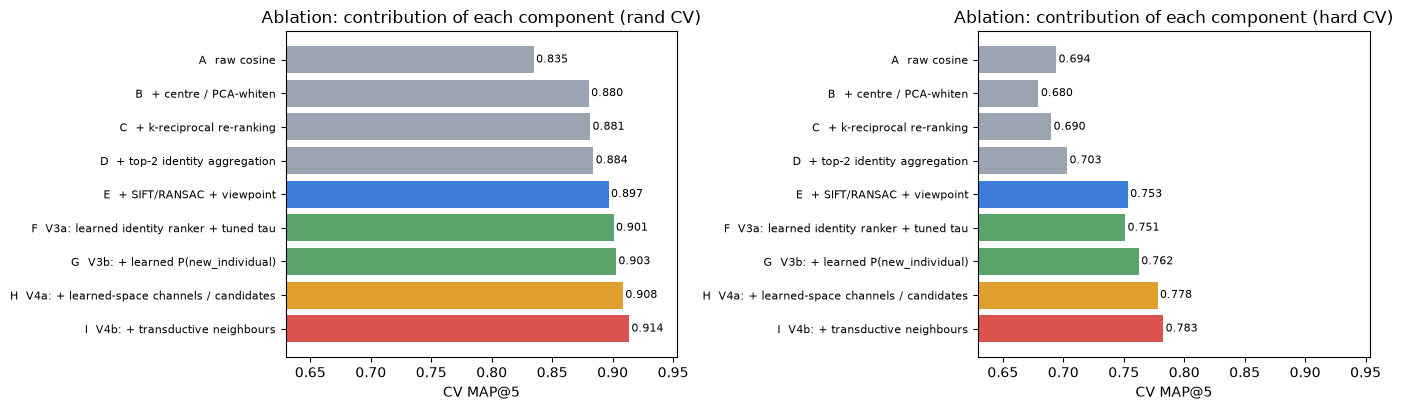

In [18]:
RESULTS_DF = pd.DataFrame(RESULTS)
RESULTS_DF = pd.concat([RESULTS_DF[RESULTS_DF.scheme == s] for s in SCH]).set_index(["scheme", "version"])
display_df = RESULTS_DF.round(4)
try: display(display_df)
except NameError: print(display_df.to_string())
RESULTS_DF.to_csv(os.path.join(OUT_DIR, "results_cv.csv"))

COL = dict(A="#9aa5b1", B="#9aa5b1", C="#9aa5b1", D="#9aa5b1", E="#3b7dd8", F="#5aa469", G="#5aa469", H="#e0a030", I="#d9534f")
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, s in zip(axs, SCH):
    d = RESULTS_DF.loc[s]; labels = [v.split("[")[0].strip() for v in d.index]
    ax.barh(range(len(d)), d["MAP@5"], color=[COL[v[0]] for v in d.index])
    ax.set_yticks(range(len(d))); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis()
    for i, v in enumerate(d["MAP@5"]): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlabel("CV MAP@5"); ax.set_title(f"Ablation: contribution of each component ({s} CV)")
lo, hi = RESULTS_DF["MAP@5"].min(), RESULTS_DF["MAP@5"].max(); axs[0].set_xlim(lo - 0.05, hi + 0.04)
savefig("ablation.png")

### Self-check: the vectorised metric equals the plain definition

In [19]:
for s in SCH:
    lists_chk = make_lists(*FIN_TOP[s], FIN_PNEW[s])
    truth_names = np.where(TCODE[s] >= 0, CLASSES[np.maximum(TCODE[s], 0)], NEW)
    ref = map5([l.split() for l in lists_chk], truth_names)
    assert abs(ref - FIN_RES[s]["ap"].mean()) < 1e-9, (s, ref, FIN_RES[s]["ap"].mean())
    print(f"[{s}] reference MAP@5 on the written-format lists = {ref:.6f}  (matches the vectorised value)")

[rand] reference MAP@5 on the written-format lists = 0.913537  (matches the vectorised value)
[hard] reference MAP@5 on the written-format lists = 0.782635  (matches the vectorised value)


## 11. Error analysis of the final model (V4)

[rand]
                                                        queries   share  MAP lost
new: a known identity ranked above NEW (false match)        292  0.0408    0.0208
known: in candidates but outside top-5 (ranking error)      137  0.0191    0.0191
known: true identity not retrieved (retrieval miss)         130  0.0181    0.0181
known: correct @2-5 (ranking error)                         180  0.0251    0.0173
known: right identity first, but NEW placed above it        159  0.0222    0.0111
new: NEW ranked 1st (correct)                              2592  0.3619    0.0000
known: correct @1                                          3673  0.5128    0.0000

total MAP lost = 0.0865  (1 - MAP@5)


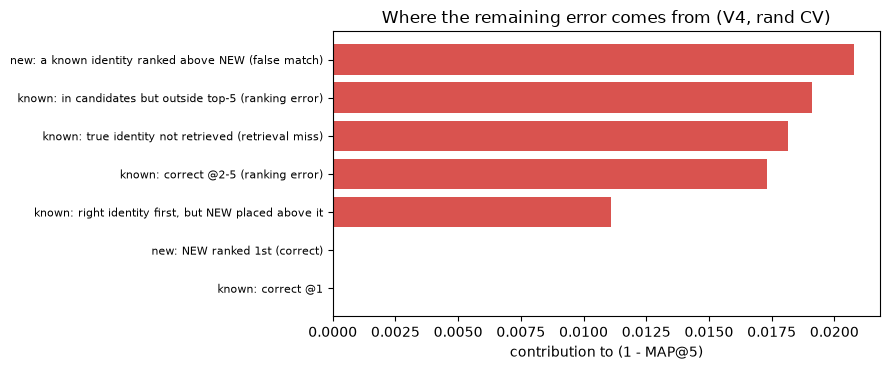

[hard]
                                                        queries   share  MAP lost
known: true identity not retrieved (retrieval miss)         508  0.0709    0.0709
known: right identity first, but NEW placed above it        692  0.0966    0.0483
known: correct @2-5 (ranking error)                         463  0.0646    0.0446
known: in candidates but outside top-5 (ranking error)      232  0.0324    0.0324
new: a known identity ranked above NEW (false match)        289  0.0403    0.0211
known: correct @1                                          2177  0.3039    0.0000
new: NEW ranked 1st (correct)                              2802  0.3912    0.0000

total MAP lost = 0.2174  (1 - MAP@5)


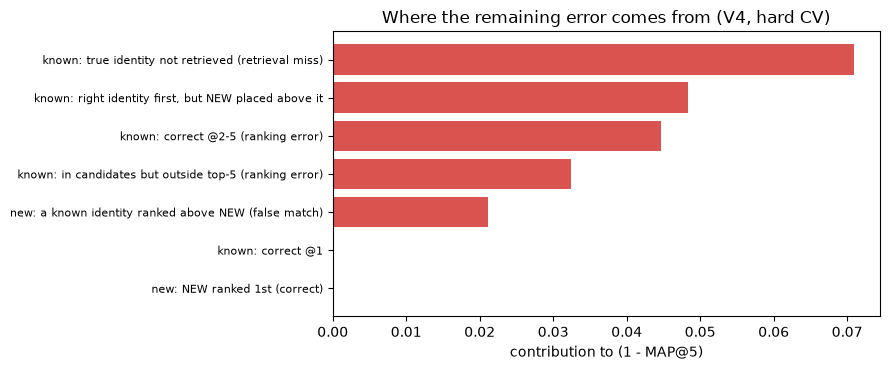

In [20]:
def failure_taxonomy(sch):
    ap, r, pos = FIN_RES[sch]["ap"], FIN_RES[sch]["r"], FIN_RES[sch]["pos"]
    tcode, has_truth = TCODE[sch], HAS[sch]
    new_q = tcode < 0; rank_final = np.where(r >= pos, r + 2, r + 1)
    cat = np.empty(len(ap), dtype=object)
    cat[new_q & (pos == 0)] = "new: NEW ranked 1st (correct)"
    cat[new_q & (pos > 0)]  = "new: a known identity ranked above NEW (false match)"
    kn = ~new_q
    cat[kn & (rank_final == 1)]                        = "known: correct @1"
    cat[kn & (r == 0) & (rank_final == 2)]             = "known: right identity first, but NEW placed above it"
    cat[kn & (rank_final >= 2) & (rank_final <= 5) & ~((r == 0) & (rank_final == 2))] = "known: correct @2-5 (ranking error)"
    cat[kn & (rank_final > 5) & has_truth]             = "known: in candidates but outside top-5 (ranking error)"
    cat[kn & ~has_truth]                               = "known: true identity not retrieved (retrieval miss)"
    tax = pd.DataFrame({"queries": pd.Series(cat).value_counts(), "share": pd.Series(cat).value_counts(normalize=True).round(4)})
    tax["MAP lost"] = [ (1 - ap[cat == c]).sum() / len(ap) for c in tax.index]
    tax = tax.sort_values("MAP lost", ascending=False)
    print(f"[{sch}]"); print(tax.round(4).to_string())
    print("\ntotal MAP lost = %.4f  (1 - MAP@5)" % (1 - ap.mean()))
    fig, ax = plt.subplots(figsize=(9, 3.8)); ax.barh(range(len(tax)), tax["MAP lost"], color="#d9534f")
    ax.set_yticks(range(len(tax))); ax.set_yticklabels(tax.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("contribution to (1 - MAP@5)")
    ax.set_title(f"Where the remaining error comes from (V4, {sch} CV)"); savefig(f"failure_taxonomy_{sch}.png")
for sch in SCH: failure_taxonomy(sch)

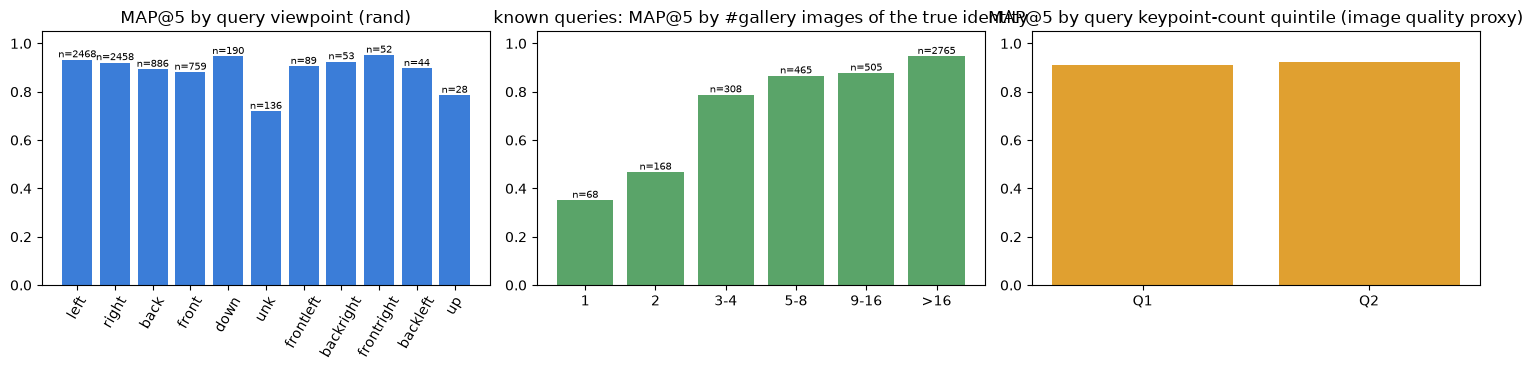

[rand]
                 mean  size
sp      new                
hyena   False  0.8959  1405
        True   0.8950   507
leopard False  0.8872  2874
        True   0.9598  2377


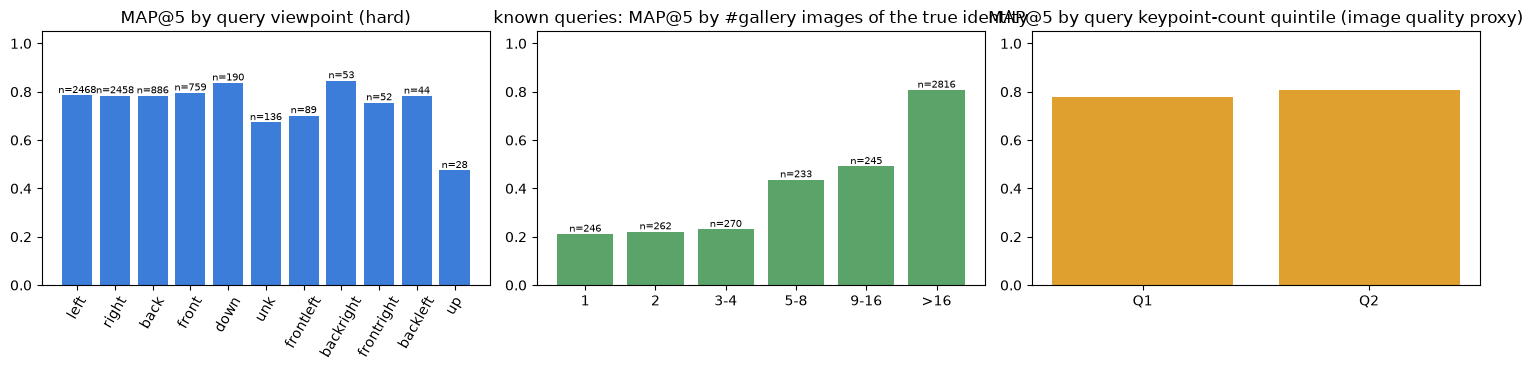

[hard]
                 mean  size
sp      new                
hyena   False  0.5768  1226
        True   0.9322   686
leopard False  0.6884  2846
        True   0.9564  2405


In [21]:
def slice_report(sch):
    ap, new_q, P = FIN_RES[sch]["ap"], TCODE[sch] < 0, POOL[sch]
    tmp = pd.DataFrame({"ident": tr.identity.to_numpy(dtype=object), "fold": FOLDS[sch][0]}); tot = tmp.groupby("ident").size(); infold = tmp.groupby(["ident", "fold"]).size()
    ident_q = tmp.ident.to_numpy()[P["q_rows"]]
    gal_size = tot.reindex(ident_q).to_numpy() - infold.reindex(pd.MultiIndex.from_arrays([ident_q, P["fold"].astype(np.int64)])).to_numpy()
    D_ = pd.DataFrame({"ap": ap, "new": new_q, "vp": np.array(VP_VOCAB)[P["q_vp"]], "kq0": P["kq"][:, 0], "gal": gal_size, "sp": np.array(SPECIES)[P["sp"]]})
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    g = D_.groupby("vp").ap.agg(["mean", "size"]).sort_values("size", ascending=False); axs[0].bar(g.index, g["mean"], color="#3b7dd8"); axs[0].set_title(f"MAP@5 by query viewpoint ({sch})"); axs[0].tick_params(axis="x", rotation=60)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): axs[0].text(i, m + 0.01, f"n={n}", ha="center", fontsize=7)
    K_ = D_[~D_.new].copy(); K_["bin"] = pd.cut(K_.gal, [0, 1, 2, 4, 8, 16, 10_000], labels=["1", "2", "3-4", "5-8", "9-16", ">16"])
    g2 = K_.groupby("bin", observed=True).ap.agg(["mean", "size"]); axs[1].bar(g2.index.astype(str), g2["mean"], color="#5aa469"); axs[1].set_title("known queries: MAP@5 by #gallery images of the true identity")
    for i, (m, n) in enumerate(zip(g2["mean"], g2["size"])): axs[1].text(i, m + 0.01, f"n={n}", ha="center", fontsize=7)
    D_["kbin"] = pd.qcut(D_.kq0.replace(0, np.nan), 5, duplicates="drop"); g3 = D_.groupby("kbin", observed=True).ap.mean()
    axs[2].bar([f"Q{i+1}" for i in range(len(g3))], g3.values, color="#e0a030"); axs[2].set_title("MAP@5 by query keypoint-count quintile (image quality proxy)")
    for a in axs: a.set_ylim(0, 1.05)
    savefig(f"slices_{sch}.png")
    print(f"[{sch}]"); print(D_.groupby(["sp", "new"]).ap.agg(["mean", "size"]).round(4))
for sch in SCH: slice_report(sch)

[rand] mean predicted P(new) on CV: 0.344 | true new share: 0.403
[hard] mean predicted P(new) on CV: 0.481 | true new share: 0.432


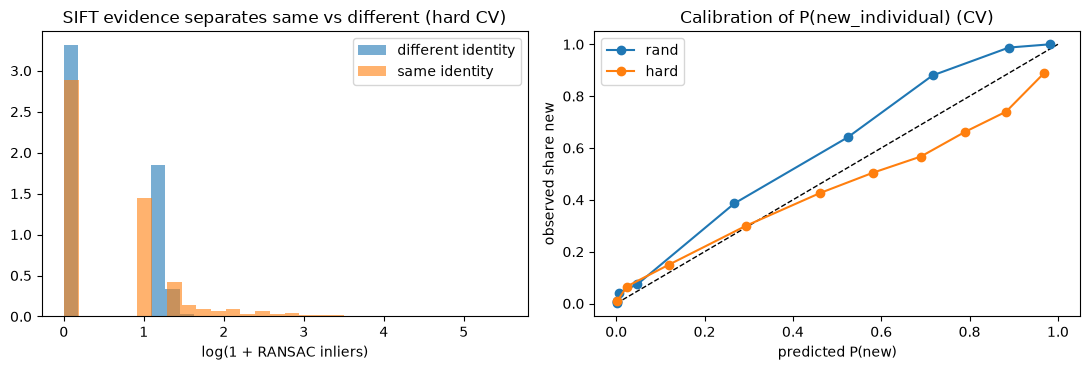

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
P_h, t_h = POOL["hard"], TCODE["hard"]
Mx = min(TOP_M_EFF, P_h["inl"].shape[1]); same_m = (P_h["gc"][:, :Mx] == t_h[:, None]) & (t_h[:, None] >= 0)
li = np.log1p(P_h["inl"][:, :Mx]); kn_rows = (t_h >= 0)[:, None] & np.ones((1, Mx), bool)
axs[0].hist(li[kn_rows & ~same_m], bins=30, alpha=.6, density=True, label="different identity"); axs[0].hist(li[same_m], bins=30, alpha=.6, density=True, label="same identity")
axs[0].set_xlabel("log(1 + RANSAC inliers)"); axs[0].set_title("SIFT evidence separates same vs different (hard CV)"); axs[0].legend()
axs[1].plot([0, 1], [0, 1], "k--", lw=1)
for s in SCH:
    pn = FIN_PNEW[s]; ynew = (TCODE[s] < 0).astype(int); bins = np.quantile(pn, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(pn, bins[1:-1]), 0, 9)
    cal = pd.DataFrame({"pred": pn, "obs": ynew, "b": idx}).groupby("b").mean(); axs[1].plot(cal.pred, cal.obs, "o-", label=s)
    print(f"[{s}] mean predicted P(new) on CV: %.3f | true new share: %.3f" % (pn.mean(), ynew.mean()))
axs[1].set_xlabel("predicted P(new)"); axs[1].set_ylabel("observed share new"); axs[1].set_title("Calibration of P(new_individual) (CV)"); axs[1].legend()
savefig("evidence_and_calibration.png")

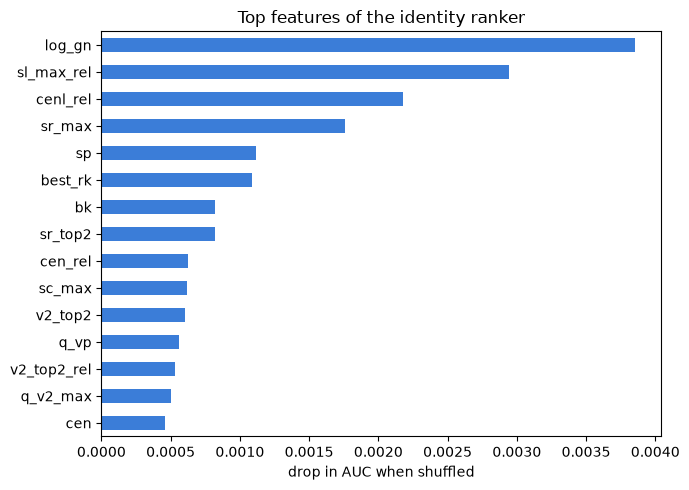

log_gn        0.0039
sl_max_rel    0.0029
cenl_rel      0.0022
sr_max        0.0018
sp            0.0011
best_rk       0.0011
bk            0.0008
sr_top2       0.0008
cen_rel       0.0006
sc_max        0.0006


In [23]:
rs = np.random.default_rng(SEED); samp = rs.choice(len(X1), min(40000, len(X1)), replace=False)
m_id_tmp = fit_hgb(X1, y1)
pi = permutation_importance(m_id_tmp, X1[samp], y1[samp], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=ID_FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5)); imp.head(15)[::-1].plot.barh(ax=ax, color="#3b7dd8"); ax.set_xlabel("drop in AUC when shuffled"); ax.set_title("Top features of the identity ranker"); savefig("feature_importance.png")
print(imp.head(10).round(4).to_string())

## 12. Final models, test inference and submission files (one per version)

* **V1**: raw cosine, max aggregation, per-species τ (mean of the two CV schemes).
* **V2**: V2 blend + top-2 aggregation, per-species τ re-tuned on the new CV (mean of the two CV schemes).
* **V3**: identity ranker and P(new) models on the V3 features, refit on **all** out-of-fold rows (both CV schemes).
* **V4**: stage 1 and stage 2 refit the same way; `submission.csv` is written from stage 2 only if `USE_S2`, otherwise from stage 1.

In [24]:
preds_by_version = {}
def to_series(lists, P):
    s = np.empty(len(te), dtype=object); s[P["q_rows"]] = lists; return s
PT = POOL["test"]; nT = len(PT["qid"]); spi = PT["sp"].astype(int)

# V1
top, sc = agg_topk(PT["r_sc"], PT["r_gc"], "max")
preds_by_version["v1"] = to_series(make_lists(top, sc, np.mean([RES_A[s]["taus"] for s in SCH], axis=0)[spi]), PT)
# V2
top, sc = agg_topk(blend(PT, BEST_PARAMS), PT["gc"], BEST_PARAMS["agg"])
preds_by_version["v2"] = to_series(make_lists(top, sc, np.mean([RES_E[s]["taus"] for s in SCH], axis=0)[spi]), PT)
# V3
m_id_v3 = fit_model(X1_v3, y1); m_new_v3 = fit_model(Xq_v3, yq)
T_te = identity_table(PT); T_te["p_v3"] = m_id_v3.predict_proba(T_te[ID_FEATS_V3].to_numpy(np.float32))[:, 1]
top_te3, sc_te3 = top_from_table(T_te, nT, "p_v3", 5)
Q_te3 = query_table(PT, T_te, "p_v3"); pnew_te3 = m_new_v3.predict_proba(Q_te3[NEW_FEATS_V3].to_numpy(np.float32))[:, 1]
preds_by_version["v3"] = to_series(make_lists(top_te3, sc_te3, pnew_te3), PT)
m_id1 = fit_model(X1, y1); m_new1 = fit_model(Xq1, yq)
T_te["p"] = m_id1.predict_proba(T_te[ID_FEATS].to_numpy(np.float32))[:, 1]
top_te1, sc_te1 = top_from_table(T_te, nT, "p", 5)
Q_te = query_table(PT, T_te, "p"); pnew_te1 = m_new1.predict_proba(Q_te[NEW_FEATS].to_numpy(np.float32))[:, 1]
preds_by_version["v4_s1"] = to_series(make_lists(top_te1, sc_te1, pnew_te1), PT)
T_te = add_neighbour_feats(PT, T_te, "p")
m_id2 = fit_model(X2, y2); m_new2 = fit_model(Xq2, yq)
T_te["p2"] = m_id2.predict_proba(T_te[ID_FEATS2].to_numpy(np.float32))[:, 1]
top_te2, sc_te2 = top_from_table(T_te, nT, "p2", 5)
Q_te2 = query_table(PT, T_te, "p2"); Q_te2["s1_p1"] = Q_te["p1"]; Q_te2["s1_pnew"] = pnew_te1
pnew_te2 = m_new2.predict_proba(Q_te2[NEW_FEATS2].to_numpy(np.float32))[:, 1]
preds_by_version["v4_s2"] = to_series(make_lists(top_te2, sc_te2, pnew_te2), PT)
log("mean predicted P(new) on TEST: V3 %.3f | stage1 %.3f | stage2 %.3f   (CV true new share: %.3f)" % (pnew_te3.mean(), pnew_te1.mean(), pnew_te2.mean(), yq.mean()))
print("  by species (stage 2):", {s: round(float(pnew_te2[PT['sp'] == i].mean()), 3) for i, s in enumerate(SPECIES)})

[  1303s] mean predicted P(new) on TEST: V3 0.298 | stage1 0.295 | stage2 0.311   (CV true new share: 0.417)
  by species (stage 2): {'hyena': 0.299, 'leopard': 0.319}


In [25]:
ss_path = f"{DATA_DIR}/sample_submission.csv"
ss = pd.read_csv(ss_path) if os.path.exists(ss_path) else None
ident_species = tr.drop_duplicates("identity").set_index("identity").species.to_dict(); test_species = te.set_index("id").species.to_dict()

prev = next((p for p in [os.environ.get("PREV_SUB"), "submission_v3.csv", os.path.join(DATA_DIR, "submission_v3.csv"), "submission.csv", os.path.join(DATA_DIR, "submission.csv")] if p and os.path.isfile(p)), None)
old = pd.read_csv(prev).set_index("id").predictions.str.split().str[0] if prev else None

def check_and_write(tag, arr):
    sub = pd.DataFrame({"id": te.id.to_numpy(), "predictions": arr})
    assert not sub.predictions.isna().any(), "NaN predictions"
    if ss is not None: assert len(sub) == len(ss) and set(sub.id) == set(ss.id) and sub.id.is_unique, "ids differ from sample_submission"
    nr = Counter()
    for i, p in zip(sub.id, sub.predictions):
        labs = p.split(); assert 1 <= len(labs) <= 5 and len(set(labs)) == len(labs), f"bad label count/dupes in {i}"
        for l in labs: assert l == NEW or (l in ident_species and ident_species[l] == test_species[i]), f"invalid label {l} for {i}"
        nr[labs.index(NEW) + 1 if NEW in labs else 0] += 1
    path = os.path.join(OUT_DIR, f"submission_{tag}.csv"); sub.to_csv(path, index=False)
    print(f"{tag}: OK -> {path} | new@1 rate {nr[1] / len(sub):.1%} | NEW absent from list: {nr[0]}")
    return sub

subs = {k: check_and_write(k, v) for k, v in preds_by_version.items()}
print(subs["v4_s2"].sample(min(6, len(te)), random_state=0).to_string(index=False))
chosen = {"v1": "v1", "v2": "v2", "v3": "v3", "v4": "v4_s2" if USE_S2 else "v4_s1"}[SUBMIT_VERSION]
subs[chosen].to_csv(os.path.join(OUT_DIR, "submission.csv"), index=False)
print(f">>> submission.csv written from version {chosen.upper()}")

if old is not None:
    for k, s in subs.items():
        cur = s.set_index("id").predictions.str.split().str[0]; common = old.index.intersection(cur.index)
        print(f"top-1 agreement of {k} with previous {prev}: {(old[common] == cur[common]).mean():.1%}")

v1: OK -> .\submission_v1.csv | new@1 rate 52.3% | NEW absent from list: 0
v2: OK -> .\submission_v2.csv | new@1 rate 39.6% | NEW absent from list: 0
v3: OK -> .\submission_v3.csv | new@1 rate 41.8% | NEW absent from list: 0
v4_s1: OK -> .\submission_v4_s1.csv | new@1 rate 41.1% | NEW absent from list: 0
v4_s2: OK -> .\submission_v4_s2.csv | new@1 rate 41.7% | NEW absent from list: 0
      id                                    predictions
te_02465 HYE0236 new_individual HYE0179 HYE0126 HYE0346
te_00689 new_individual LEO0614 LEO0422 LEO0391 LEO0412
te_02684 new_individual HYE0675 HYE0350 HYE0512 HYE0126
te_00992 HYE0524 new_individual HYE0398 HYE0034 HYE0577
te_00617 HYE0188 HYE0125 new_individual HYE0677 HYE0400
te_00228 new_individual LEO0156 LEO0386 LEO0463 LEO0230
>>> submission.csv written from version V4_S2
top-1 agreement of v1 with previous submission_v3.csv: 80.0%
top-1 agreement of v2 with previous submission_v3.csv: 89.7%
top-1 agreement of v3 with previous submission_v3.csv